# Snap-through and snap-back of a hinged cylindrical roof: Donnell, Sanders, Green-Lagrange and total-Lagrangian kinematics

The hinged cylindrical roof of Sabir and Lock (1972), as given by Sze, Liu and Lo (2004), Section 3.8, is loaded by a central point action. With the thickness $h = 12.7$ the load passes through a maximum and a minimum while the central deflection keeps increasing (snap-through); with $h = 6.35$ the central deflection itself turns back (snap-back), so that neither a load-controlled nor a displacement-controlled incremental analysis can follow the whole path. The path is traced here with the Riks method of `structsolve`, the central deflection being prescribed and the reaction at the centre tracked, for the four cylindrical-shell models of panels with the classical laminated plate theory (CLPT):

- `'cylshell_clpt_donnell'`: Donnell's shallow-shell kinematics, the non-linear terms of $w$ only;
- `'cylshell_clpt_sanders'`: the Sanders-Koiter kinematics, with the rotation $\phi_y = -w_{,y} + v/r$ in the non-linear terms, the default model of the cylinders;
- `'cylshell_clpt_gl'`: the complete Green-Lagrange membrane strains (Flügge-Lur'e-Byrne strains of Amabili 2008, Eqs. 1.118-1.120) with Sanders' linear changes of curvature;
- `'cylshell_clpt_tl'`: total-Lagrangian Kirchhoff-Love, the Green-Lagrange membrane strains and the changes of curvature of the deformed normal, invariant under any rigid rotation.

Section 6 adds the first-order shear deformation (FSDT) cylinders, which do not converge under the point load, and Section 7 replaces the point load by a small uniformly loaded patch, on which they converge, for a converged comparison with Sze et al.

The kinematics are described in [Shells: overview](../shell_overview.rst) and in [`panels.models`](../models.rst).

**Problem** (Sze et al. 2004, Fig. 9a): radius $R = 2540$, axial length $2L = 508$, half-angle $\theta = 0.1$ rad (straight edges $2R\theta = 508$ apart), isotropic, $E = 3102.75$, $\nu = 0.3$, $h = 12.7$ and $6.35$, consistent units. The straight edges are hinged, all translations restrained and the rotation about the edge free; the curved edges are free. The reference values are the load-deflection paths of Sze et al., Tables 9a ($h = 12.7$) and 9d ($h = 6.35$), $P/P_{max}$ with $P_{max} = 3000$ against the central deflection $-W_C$, obtained with ABAQUS S4R elements; the tables give the whole paths, so no curve is digitised.

References:

- A. B. Sabir and A. C. Lock, "The application of finite elements to the large deflection geometrically nonlinear behaviour of cylindrical shells", in: C. A. Brebbia and H. Tottenham (eds.), *Variational Methods in Engineering*, Southampton University Press, 1972, 7/54-7/65 (reference [4] of Sze et al. 2004, not read; the data are those of Sze et al.).
- K. Y. Sze, X. H. Liu and S. H. Lo, "Popular benchmark problems for geometric nonlinear analysis of shells", *Finite Elements in Analysis and Design* 40 (2004) 1551-1569, https://doi.org/10.1016/j.finel.2003.11.001, Section 3.8, Fig. 9 and Table 9.
- M. Amabili, *Nonlinear Vibrations and Stability of Shells and Plates*, Cambridge University Press, 2008, https://doi.org/10.1017/CBO9780511619694, Chapter 1.
- J. L. Sanders, "Nonlinear theories for thin shells", *Quarterly of Applied Mathematics* 21(1) (1963) 21-36, https://doi.org/10.1090/qam/147023.
- A. M. A. van der Heijden (ed.), *W. T. Koiter's Elastic Stability of Solids and Structures*, Cambridge University Press, 2008, https://doi.org/10.1017/CBO9780511546174, Sec. 3.16.
- R. D. Mindlin, "Influence of rotatory inertia and shear on flexural motions of isotropic, elastic plates", *Journal of Applied Mechanics* 18(1) (1951) 31-38, https://doi.org/10.1115/1.4010217.
- R. Schmidt and J. N. Reddy, "A refined small strain and moderate rotation theory of elastic anisotropic shells", *Journal of Applied Mechanics* 55(3) (1988) 611-617, https://doi.org/10.1115/1.3125837.
- A. F. Palmerio, J. N. Reddy and R. Schmidt, "On a moderate rotation theory of laminated anisotropic shells - Part 1. Theory", *International Journal of Non-Linear Mechanics* 25(6) (1990) 687-700, https://doi.org/10.1016/0020-7462(90)90007-V.
- E. Riks, "An incremental approach to the solution of snapping and buckling problems", *International Journal of Solids and Structures* 15(7) (1979) 529-551, https://doi.org/10.1016/0020-7683(79)90081-7.

In [1]:
%matplotlib inline
import os
import sys
import json
import time
import multiprocessing
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# the roof and the Riks analysis are those of the tests of the model
sys.path.insert(0, '../tests/tests_shell')
import test_cylshell_clpt_tl as tt

# True runs panels again, otherwise the results saved in RESULTS are loaded
RERUN = True
RESULTS = os.path.join('results', 'sabir1972_roof_snap_back.json')

MODELS = [tt.DONNELL, tt.SANDERS, tt.GL, tt.TL]
LABELS = {tt.DONNELL: 'Donnell', tt.SANDERS: 'Sanders', tt.GL: 'GL', tt.TL: 'TL'}
THICKNESSES = (12.7, 6.35)
SZE = {12.7: tt.SZE_9A, 6.35: tt.SZE_9D}


def table(header, rows):
    lines = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    lines += ['| ' + ' | '.join(str(v) for v in row) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))


def pct(value, ref):
    return 100*(value - ref)/abs(ref)

## 1. Model

**Quarter of the roof.** The roof, the supports and the load are symmetric about the two mid-planes, and the paths of Sze et al. are symmetric, so one quarter is modelled, `tt.hinged_roof(model, h, m)`: a cylindrical panel $0 \le x \le L$ (axial), $0 \le y \le R\theta$ (arc length), with

- the hinged straight edge at $y = 0$: $u = v = w = 0$, the slope $w_{,y}$ free;
- the free curved edge at $x = 0$;
- the plane of symmetry $x = L$: $u = 0$, $v_{,x} = 0$, $w_{,x} = 0$;
- the plane of symmetry $y = R\theta$: $v = 0$, $u_{,y} = 0$, $w_{,y} = 0$;

with $m \times m$ terms of Bardell's functions, whose boundary flags impose these conditions; the centre of the roof is the corner $(L, R\theta)$ of the quarter. A symmetric quarter cannot follow an asymmetric bifurcation; Sze et al. report none on these paths.

**Prescribed central deflection, tracked reaction.** The deflection of the centre, $w_C = \boldsymbol{e}^\top \boldsymbol{c}$ with $\boldsymbol{c}$ the Ritz constants, is prescribed through a stiff spring, `tt.roof_path`: its stiffness is $K = 100$ times the linear stiffness of the centre, and its other end moves by $\lambda\delta$, $\delta = -w_{max}$, with $\lambda$ the load factor of the Riks method (Riks 1979). The spring adds $K\boldsymbol{e}\boldsymbol{e}^\top$ to the tangent stiffness and $K\boldsymbol{e}(\boldsymbol{e}^\top\boldsymbol{c})$ to the internal forces, and the external force is $\lambda K\delta\boldsymbol{e}$:

```python
def calc_fext(inc=1., silent=True):
    return inc*K*delta*e

def calc_fint(c, silent=True):
    return s.calc_fint(c) + K*e*(e @ c)

def calc_kC(c=None, NLgeom=False, silent=True):
    return s.calc_kC(c=c, NLgeom=NLgeom) + Ke

an = Analysis(calc_fext, calc_fint, calc_kC, s.calc_kG)
an.NL_method = 'arc_length_riks'
an.initialInc = an.maxInc = 0.01
an.final_load_factor = None
an.stop_criterion = lambda an: -(e @ an.cs[-1]) >= wmax
```

The reaction of the roof on the point of application, for the whole roof, is the force of the spring, $P = 4K(w_C - \lambda\delta)$, positive downwards, at every converged increment; it does not depend on $K$, which only sets how the path is parametrised. The Riks method controls the arc length in the space of $\boldsymbol{c}$ and $\lambda$, so it follows the path where the prescribed displacement $\lambda\delta$ must turn back, i.e. through the snap-back of $w_C$, where a displacement-controlled analysis stops. The paths are traced until $-w_C = 30$ ($h = 12.7$) and $39$ ($h = 6.35$), beyond the last points of the tables of Sze et al.

**Integration.** Every model uses its default number of Gauss-Legendre points, exact for its integrands: $2p + 1$ along each direction for the first three, $3p + 1$ for `'cylshell_clpt_tl'`, whose curvatures are cubic in the displacements, with $p = \max(m - 1, 3)$ the degree of the approximation functions.

## 2. Computation

Every model and thickness is traced with $m \times m$ terms, $m$ = 6, 8, 10, 12 and 14, for the convergence of the Ritz approximation; $m = 12$ is the setting compared below. `compute()` runs the analyses in parallel processes, one per core, and saves the paths in `results/sabir1972_roof_snap_back.json`; with `RERUN = False` that file is loaded instead. The column `time` of the tables is the wall time of each run on the cluster node that executed this notebook (hpc12, 8 cores, 8 runs at a time).

In [2]:
M_CONV = (6, 8, 10, 12, 14)
M_MAIN = 12


def run(args):
    model, h, m = args
    t0 = time.time()
    P, wc, lbd = tt.roof_path(model, h, m)
    return dict(model=model, h=h, m=m, P=P.tolist(), wc=wc.tolist(),
                lbd=lbd.tolist(), time=time.time() - t0)


def compute():
    jobs = [(model, h, m) for h in THICKNESSES for model in MODELS for m in M_CONV]
    # the longest runs first: many terms, the total-Lagrangian model, the thin roof
    jobs.sort(key=lambda j: (-j[2], j[0] != tt.TL, j[1]))
    with ProcessPoolExecutor(max_workers=os.cpu_count(),
                             mp_context=multiprocessing.get_context('fork')) as ex:
        outs = list(ex.map(run, jobs))
    return {'%s h%g m%d' % (o['model'], o['h'], o['m']): o for o in outs}


t0 = time.time()
if RERUN or not os.path.exists(RESULTS):
    res = compute()
    os.makedirs(os.path.dirname(RESULTS), exist_ok=True)
    with open(RESULTS, 'w') as f:
        json.dump(res, f)
else:
    with open(RESULTS) as f:
        res = json.load(f)
print('%d paths, wall time of the cell %.0f s, sum of the run times %.0f s'
      % (len(res), time.time() - t0, sum(o['time'] for o in res.values())))


def path(model, h, m=None):
    o = res['%s h%g m%d' % (model, h, M_MAIN if m is None else m)]
    return np.r_[0., o['P']], -np.r_[0., o['wc']], o

40 paths, wall time of the cell 2307 s, sum of the run times 13314 s


## 3. Load-deflection paths

The reaction $P$ against the central deflection $-w_C$, with $m = 12$, and the points of Tables 9a and 9d of Sze et al. ($P = 3000\,P/P_{max}$). For $h = 6.35$ the deflection grows to about 17, turns back to about 14.5 while the reaction becomes negative (the roof has to be held up), and grows again: the snap-back, followed by the Riks method under the prescribed central deflection.

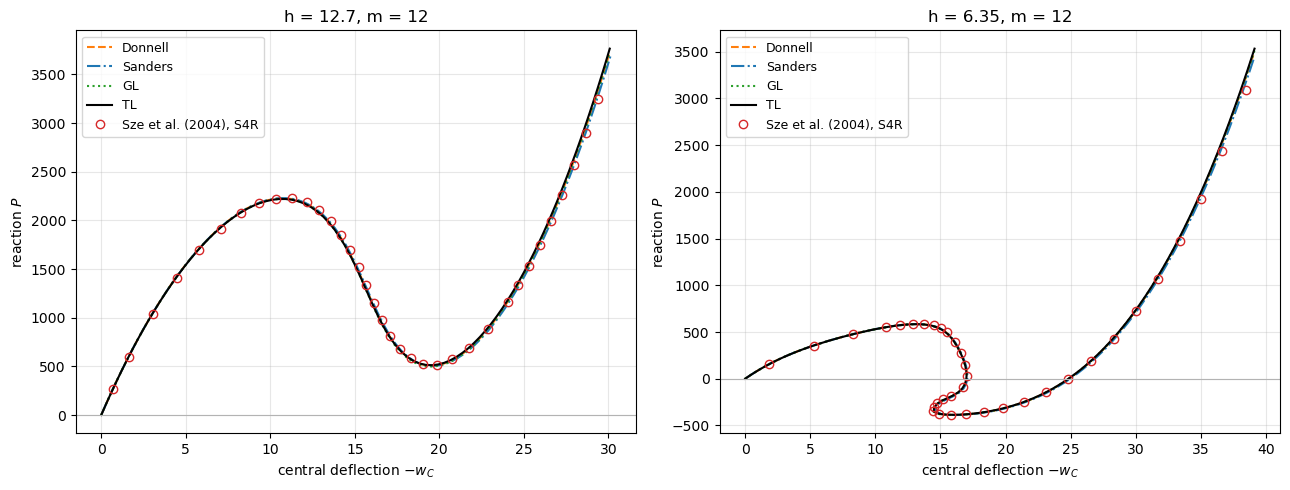

In [3]:
styles = {tt.DONNELL: dict(color='tab:orange', ls='--'), tt.SANDERS: dict(color='tab:blue', ls='-.'),
          tt.GL: dict(color='tab:green', ls=':'), tt.TL: dict(color='k', ls='-')}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, h in zip(axes, THICKNESSES):
    for model in MODELS:
        P, w, _ = path(model, h)
        ax.plot(w, P, label=LABELS[model], lw=1.5, **styles[model])
    ref = SZE[h]
    ax.plot(ref[:, 1], tt.PMAX*ref[:, 0], 'o', mfc='none', mec='tab:red', ms=6,
            label='Sze et al. (2004), S4R')
    ax.axhline(0., color='0.7', lw=0.8)
    ax.set_title('h = %g, m = %d' % (h, M_MAIN))
    ax.set_xlabel('central deflection $-w_C$')
    ax.set_ylabel('reaction $P$')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 4. Characteristic points

The critical points of the paths, each refined with a parabola through the three converged increments around it, as a function of the length along the path in the plane of $P/P_{max}$ and $w_C/h$:

- $P_1$: the first maximum of the reaction, the limit point of the snap-through;
- $P_2$: the following minimum of the reaction;
- for $h = 6.35$, $w_3$ and $w_4$: the maximum of the deflection before the snap-back and the minimum after it.

Each value is compared with the same point of the tables of Sze et al., taken at the tabulated point of the extremum (the tables are not refined), with the relative difference in parentheses. `dist` is the largest distance of the points of the table from the path of panels, in the plane of $P/P_{max}$ and $-w_C/h$, a measure of the agreement of the whole path.

In [4]:
def arc(P, w, h):
    d = np.hypot(np.diff(P/tt.PMAX), np.diff(w/h))
    return np.r_[0., np.cumsum(d)]


def refine(f, g, s, i):
    # vertex of the parabola of f(s) through i - 1, i, i + 1, and g there
    if i <= 0 or i >= len(f) - 1:
        return f[i], g[i]
    ss = s[i-1:i+2]
    a = np.polyfit(ss, f[i-1:i+2], 2)
    s0 = -a[1]/(2*a[0])
    return np.polyval(a, s0), np.polyval(np.polyfit(ss, g[i-1:i+2], 2), s0)


def first_turn(f, start, down=True):
    # index of the first local extremum of f after start: a maximum
    # (down=True) or a minimum
    d = np.diff(f[start:])
    k = np.argmax(d < 0) if down else np.argmax(d > 0)
    return start + int(k)


def extrema(P, w, h):
    s = arc(P, w, h)
    i1 = first_turn(P, 0, True)
    i2 = first_turn(P, i1, False)
    out = {'P1': refine(P, w, s, i1), 'P2': refine(P, w, s, i2)}
    if h < 10:
        i3 = first_turn(w, 0, True)
        i4 = first_turn(w, i3, False)
        out['w3'] = refine(w, P, s, i3)[::-1]
        out['w4'] = refine(w, P, s, i4)[::-1]
    return out


def sze_extrema(h):
    P, w = tt.PMAX*SZE[h][:, 0], SZE[h][:, 1]
    i1 = first_turn(P, 0, True)
    i2 = first_turn(P, i1, False)
    out = {'P1': (P[i1], w[i1]), 'P2': (P[i2], w[i2])}
    if h < 10:
        i3 = first_turn(w, 0, True)
        i4 = first_turn(w, i3, False)
        out['w3'] = (P[i3], w[i3])
        out['w4'] = (P[i4], w[i4])
    return out


def distance(P, w, h):
    # largest distance of the points of the table from the polyline of the path
    pts = np.c_[SZE[h][:, 0], SZE[h][:, 1]/h]
    poly = np.c_[P/tt.PMAX, w/h]
    a, b = poly[:-1], poly[1:]
    worst = 0.
    for p in pts:
        t = np.clip(np.einsum('ij,ij->i', p - a, b - a)/np.einsum('ij,ij->i', b - a, b - a), 0, 1)
        worst = max(worst, np.min(np.linalg.norm(a + t[:, None]*(b - a) - p, axis=1)))
    return worst


for h in THICKNESSES:
    ref = sze_extrema(h)
    keys = list(ref)
    rows = [['Sze et al.'] + ['%.1f / %.3f' % ref[k] for k in keys] + ['-', '-', '-']]
    for model in MODELS:
        P, w, o = path(model, h)
        ex = extrema(P, w, h)
        row = [LABELS[model]]
        for k in keys:
            Pk, wk = ex[k]
            if k.startswith('P'):
                row.append('%.1f (%+.2f%%) / %.3f' % (Pk, pct(Pk, ref[k][0]), wk))
            else:
                row.append('%.1f / %.3f (%+.2f%%)' % (Pk, wk, pct(wk, ref[k][1])))
        row += ['%.4f' % distance(P, w, h), '%d' % len(o['P']), '%.0f s' % o['time']]
        rows.append(row)
    display(Markdown('**h = %g**, $m = %d$, values $P$ / $-w_C$' % (h, M_MAIN)))
    table(['model'] + keys + ['dist', 'increments', 'time'], rows)

**h = 12.7**, $m = 12$, values $P$ / $-w_C$

| model | P1 | P2 | dist | increments | time |
|---|---|---|---|---|---|
| Sze et al. | 2226.3 / 11.293 | 518.7 / 19.852 | - | - | - |
| Donnell | 2227.4 (+0.05%) / 10.732 | 507.0 (-2.25%) / 19.524 | 0.0107 | 91 | 398 s |
| Sanders | 2229.4 (+0.14%) / 10.752 | 504.6 (-2.72%) / 19.589 | 0.0060 | 91 | 632 s |
| GL | 2222.0 (-0.19%) / 10.714 | 497.7 (-4.05%) / 19.504 | 0.0108 | 91 | 93 s |
| TL | 2220.5 (-0.26%) / 10.714 | 511.6 (-1.38%) / 19.483 | 0.0152 | 91 | 269 s |

**h = 6.35**, $m = 12$, values $P$ / $-w_C$

| model | P1 | P2 | w3 | w4 | dist | increments | time |
|---|---|---|---|---|---|---|---|
| Sze et al. | 585.9 / 12.892 | -386.4 / 15.778 | 24.9 / 17.008 | -342.6 / 14.451 | - | - | - |
| Donnell | 585.5 (-0.07%) / 13.144 | -387.7 (-0.35%) / 16.023 | 39.0 / 17.032 (+0.14%) | -361.5 / 14.470 (+0.13%) | 0.0323 | 141 | 576 s |
| Sanders | 585.8 (-0.01%) / 13.157 | -388.0 (-0.42%) / 16.137 | 34.2 / 17.076 (+0.40%) | -362.0 / 14.621 (+1.17%) | 0.0274 | 140 | 900 s |
| GL | 584.2 (-0.29%) / 13.128 | -388.0 (-0.42%) / 15.954 | 37.4 / 17.010 (+0.01%) | -361.9 / 14.405 (-0.32%) | 0.0344 | 142 | 133 s |
| TL | 584.6 (-0.21%) / 13.133 | -386.1 (+0.09%) / 16.009 | 39.3 / 17.011 (+0.02%) | -361.4 / 14.477 (+0.18%) | 0.0385 | 141 | 379 s |

### End of the paths and the turn of the prescribed deflection

The reaction at the last deflection of the tables, $-w_C = 29.374$ ($h = 12.7$) and $38.450$ ($h = 6.35$), interpolated along the last rising branch of each path, and the number of increments in which the prescribed displacement $\lambda\delta$ of the spring decreases, i.e. in which the Riks method follows the snap-back.

In [5]:
rows = []
for h in THICKNESSES:
    wref, Pref = SZE[h][-1, 1], tt.PMAX*SZE[h][-1, 0]
    for model in MODELS:
        P, w, o = path(model, h)
        row = [h, LABELS[model], '%.1f' % Pref]
        for m in (M_MAIN, max(M_CONV)):
            P, w, o = path(model, h, m)
            k = int(np.argmax(w > wref))
            Pi = np.interp(wref, w[k-1:k+1], P[k-1:k+1])
            row.append('%.1f (%+.2f%%)' % (Pi, pct(Pi, Pref)))
        P, w, o = path(model, h)
        row.append(int(np.sum(np.diff(o['lbd']) < 0)))
        rows.append(row)
table(['$h$', 'model', 'Sze et al.: $P$', '$P$, $m = %d$' % M_MAIN, '$P$, $m = %d$' % max(M_CONV),
       r'increments with decreasing $\lambda$, $m = %d$' % M_MAIN], rows)

| $h$ | model | Sze et al.: $P$ | $P$, $m = 12$ | $P$, $m = 14$ | increments with decreasing $\lambda$, $m = 12$ |
|---|---|---|---|---|---|
| 12.7 | Donnell | 3250.5 | 3330.3 (+2.45%) | 3329.9 (+2.44%) | 0 |
| 12.7 | Sanders | 3250.5 | 3272.4 (+0.68%) | 3271.9 (+0.66%) | 0 |
| 12.7 | GL | 3250.5 | 3331.3 (+2.49%) | 3330.7 (+2.47%) | 0 |
| 12.7 | TL | 3250.5 | 3365.0 (+3.52%) | 3364.5 (+3.51%) | 0 |
| 6.35 | Donnell | 3093.9 | 3222.3 (+4.15%) | 3217.8 (+4.01%) | 10 |
| 6.35 | Sanders | 3093.9 | 3170.3 (+2.47%) | 3165.9 (+2.33%) | 10 |
| 6.35 | GL | 3093.9 | 3230.5 (+4.42%) | 3226.1 (+4.27%) | 10 |
| 6.35 | TL | 3093.9 | 3247.3 (+4.96%) | 3242.9 (+4.81%) | 10 |

## 5. Convergence of the Ritz approximation

The limit load $P_1$ and the minimum $P_2$ of each model with $m \times m$ terms, $m$ = 6, 8, 10, 12 and 14, with the difference from the largest $m$ in parentheses; for $h = 6.35$ also the deflections $w_3$ and $w_4$ of the snap-back.

In [6]:
for h in THICKNESSES:
    keys = ['P1', 'P2'] + (['w3', 'w4'] if h < 10 else [])
    rows = []
    for model in MODELS:
        best = extrema(*path(model, h, max(M_CONV))[:2], h)
        for m in M_CONV:
            P, w, o = path(model, h, m)
            ex = extrema(P, w, h)
            row = [LABELS[model], m]
            for k in keys:
                j = 0 if k.startswith('P') else 1
                row.append('%.2f (%+.2f%%)' % (ex[k][j], pct(ex[k][j], best[k][j])))
            row += ['%.4f' % distance(P, w, h), '%.0f s' % o['time']]
            rows.append(row)
    display(Markdown('**h = %g**' % h))
    table(['model', 'm'] + keys + ['dist', 'time'], rows)

**h = 12.7**

| model | m | P1 | P2 | dist | time |
|---|---|---|---|---|---|
| Donnell | 6 | 2227.84 (+0.02%) | 506.57 (-0.10%) | 0.0158 | 11 s |
| Donnell | 8 | 2227.52 (+0.01%) | 506.89 (-0.03%) | 0.0117 | 45 s |
| Donnell | 10 | 2227.41 (+0.00%) | 507.01 (-0.01%) | 0.0109 | 149 s |
| Donnell | 12 | 2227.39 (+0.00%) | 507.02 (-0.01%) | 0.0107 | 398 s |
| Donnell | 14 | 2227.33 (+0.00%) | 507.06 (+0.00%) | 0.0105 | 946 s |
| Sanders | 6 | 2229.80 (+0.02%) | 504.14 (-0.10%) | 0.0081 | 15 s |
| Sanders | 8 | 2229.49 (+0.01%) | 504.45 (-0.04%) | 0.0066 | 72 s |
| Sanders | 10 | 2229.38 (+0.00%) | 504.58 (-0.01%) | 0.0061 | 241 s |
| Sanders | 12 | 2229.37 (+0.00%) | 504.58 (-0.01%) | 0.0060 | 632 s |
| Sanders | 14 | 2229.30 (+0.00%) | 504.63 (+0.00%) | 0.0061 | 1585 s |
| GL | 6 | 2222.54 (+0.02%) | 497.26 (-0.10%) | 0.0159 | 5 s |
| GL | 8 | 2222.23 (+0.01%) | 497.43 (-0.06%) | 0.0118 | 13 s |
| GL | 10 | 2222.12 (+0.00%) | 497.69 (-0.01%) | 0.0110 | 37 s |
| GL | 12 | 2222.03 (+0.00%) | 497.70 (-0.01%) | 0.0108 | 93 s |
| GL | 14 | 2222.03 (+0.00%) | 497.74 (+0.00%) | 0.0107 | 201 s |
| TL | 6 | 2220.96 (+0.02%) | 511.01 (-0.11%) | 0.0203 | 10 s |
| TL | 8 | 2220.64 (+0.01%) | 511.29 (-0.06%) | 0.0162 | 35 s |
| TL | 10 | 2220.53 (+0.00%) | 511.43 (-0.03%) | 0.0155 | 114 s |
| TL | 12 | 2220.45 (+0.00%) | 511.57 (-0.01%) | 0.0152 | 269 s |
| TL | 14 | 2220.45 (+0.00%) | 511.60 (+0.00%) | 0.0151 | 614 s |

**h = 6.35**

| model | m | P1 | P2 | w3 | w4 | dist | time |
|---|---|---|---|---|---|---|---|
| Donnell | 6 | 588.63 (+0.54%) | -388.21 (-0.11%) | 16.95 (-0.47%) | 14.51 (+0.39%) | 0.0896 | 14 s |
| Donnell | 8 | 585.55 (+0.01%) | -387.69 (+0.03%) | 17.03 (-0.01%) | 14.51 (+0.38%) | 0.0452 | 66 s |
| Donnell | 10 | 585.49 (+0.00%) | -387.65 (+0.04%) | 17.03 (+0.00%) | 14.48 (+0.14%) | 0.0352 | 211 s |
| Donnell | 12 | 585.48 (+0.00%) | -387.74 (+0.02%) | 17.03 (-0.00%) | 14.47 (+0.10%) | 0.0323 | 576 s |
| Donnell | 14 | 585.48 (+0.00%) | -387.80 (+0.00%) | 17.03 (+0.00%) | 14.46 (+0.00%) | 0.0313 | 1373 s |
| Sanders | 6 | 589.01 (+0.54%) | -388.56 (-0.13%) | 17.00 (-0.48%) | 14.66 (+0.42%) | 0.0759 | 23 s |
| Sanders | 8 | 585.91 (+0.01%) | -388.00 (+0.02%) | 17.08 (-0.01%) | 14.64 (+0.27%) | 0.0320 | 104 s |
| Sanders | 10 | 585.84 (+0.00%) | -387.97 (+0.03%) | 17.08 (-0.00%) | 14.61 (+0.05%) | 0.0252 | 333 s |
| Sanders | 12 | 585.84 (+0.00%) | -388.02 (+0.01%) | 17.08 (-0.01%) | 14.62 (+0.14%) | 0.0274 | 900 s |
| Sanders | 14 | 585.83 (+0.00%) | -388.07 (+0.00%) | 17.08 (+0.00%) | 14.60 (+0.00%) | 0.0243 | 2307 s |
| GL | 6 | 587.36 (+0.54%) | -388.53 (-0.11%) | 16.93 (-0.48%) | 14.44 (+0.29%) | 0.0920 | 6 s |
| GL | 8 | 584.28 (+0.01%) | -387.98 (+0.03%) | 17.01 (-0.01%) | 14.46 (+0.45%) | 0.0473 | 19 s |
| GL | 10 | 584.22 (+0.00%) | -387.95 (+0.04%) | 17.01 (+0.00%) | 14.42 (+0.19%) | 0.0373 | 55 s |
| GL | 12 | 584.21 (+0.00%) | -388.03 (+0.02%) | 17.01 (-0.00%) | 14.40 (+0.08%) | 0.0344 | 133 s |
| GL | 14 | 584.21 (+0.00%) | -388.10 (+0.00%) | 17.01 (+0.00%) | 14.39 (+0.00%) | 0.0333 | 274 s |
| TL | 6 | 587.73 (+0.53%) | -386.55 (-0.10%) | 16.93 (-0.47%) | 14.53 (+0.59%) | 0.0954 | 13 s |
| TL | 8 | 584.71 (+0.01%) | -386.08 (+0.02%) | 17.01 (-0.01%) | 14.49 (+0.27%) | 0.0512 | 49 s |
| TL | 10 | 584.65 (+0.00%) | -386.01 (+0.04%) | 17.01 (+0.00%) | 14.46 (+0.05%) | 0.0414 | 160 s |
| TL | 12 | 584.64 (+0.00%) | -386.06 (+0.02%) | 17.01 (+0.00%) | 14.48 (+0.20%) | 0.0385 | 379 s |
| TL | 14 | 584.64 (+0.00%) | -386.16 (+0.00%) | 17.01 (+0.00%) | 14.45 (+0.00%) | 0.0374 | 831 s |

## 6. Stiffness at the end of the paths: transverse shear and the control method

At the end of the paths every CLPT model is stiffer than the S4R paths of Sze et al. (Section 4), with converged values (Section 5). The ABAQUS element S4R is shear deformable: its formulation changes from that of a discrete Kirchhoff shell to that of a thick shell as the thickness increases (Sze et al. 2004, Sec. 3, Table 1, p. 1554), and Sze et al. used $16 \times 16$ ($h = 12.7$) and $24 \times 24$ ($h = 6.35$) elements on the quarter (footnotes of Table 9, p. 1566). Under a point load the transverse shear adds a local deflection at the centre, absent from the CLPT. This section repeats the quarter roof with the first-order shear deformation theory (FSDT) cylinders of panels, `'cylshell_fsdt_donnell'` and `'cylshell_fsdt_sanders'`, against their CLPT counterparts, and tests the other parameters of the analysis that could change the end of the paths:

- **FSDT.** 5 degrees of freedom per term, the rotations $\phi_x$, $\phi_y$ independent, the shear correction of Rohwer (the default of `Shell`, $5/6$ for a homogeneous plate), $m$ = 8 to 16. Besides the Donnell and Sanders kinematics, `'cylshell_fsdt_gl'`: the Green-Lagrange membrane strains of `'cylshell_clpt_gl'` with the linear bending and transverse shear strains of `'cylshell_fsdt_sanders'`, compared with `'cylshell_clpt_gl'`. The boundary conditions are those of Section 1, with, for the rotations, $\phi_x = 0$ and $\phi_{y,x} = 0$ on the plane of symmetry $x = L$, $\phi_y = 0$ and $\phi_{x,y} = 0$ on $y = R\theta$; on the hinged edge $\phi_y$ (the rotation about the edge) is free, and $\phi_x$ free (soft hinge, as the free rotations of the S4R nodes) or zero (hard hinge).
- **Consistency of the FSDT model.** The transverse shear stiffness multiplied by $10^4$ (`fsdt_shear_correction = 1e4`) must give the CLPT path.
- **Control method.** The stiffness of the spring that prescribes the central deflection, $K$ = 10 and 1000 instead of 100 times the linear stiffness of the centre, and the increments halved (`max_inc = 0.005`): the reaction must not change.

The table gives the limit load $P_1$, the reaction at the last deflection of the tables (interpolated as in Section 4, $-w_C = 29.374$ and $38.450$) with its difference from Sze et al., the difference from the CLPT model of the same kinematics and $m$ (or $m = 12$), and $k_C$, the linear stiffness of the centre of the roof (the force for a unit central deflection, whole roof). The 40 paths of the Donnell and Sanders kinematics take about 1.7 hours on 8 cores of hpc12, the 14 paths of the Green-Lagrange models are added to them; their results are stored in `results/sabir1972_roof_snap_back_shear.json` (`RERUN_SHEAR = True` runs them again).

In [7]:
from scipy.sparse import csr_matrix
from structsolve import Analysis, solve
from panels.shell import Shell
from panels.models import clpt_field, fsdt_tsdt_field

RERUN_SHEAR = False
RESULTS_SHEAR = os.path.join('results', 'sabir1972_roof_snap_back_shear.json')


def roof(model, h, m, hinge='soft', scf=None):
    # quarter of the roof of tt.hinged_roof, also for the FSDT
    s = Shell(model=model, a=tt.ROOF_A/2, b=tt.ROOF_B/2, r=tt.ROOF_R, stack=[0.], plyt=h,
              laminaprop=(tt.ROOF_E, tt.ROOF_NU), m=m, n=m)
    fields = ['u', 'v', 'w'] + (['phix', 'phiy'] if 'fsdt' in model else [])
    for edge in ('x1', 'x2', 'y1', 'y2'):
        for f in fields:
            setattr(s, edge + f, 1.)
            setattr(s, edge + f + 'r', 1.)
    s.y1u = s.y1v = s.y1w = 0.          # hinged straight edge
    s.x2u = s.x2vr = s.x2wr = 0.        # symmetry x = L
    s.y2v = s.y2ur = s.y2wr = 0.        # symmetry y = R theta
    if 'fsdt' in model:
        s.x2phix = s.x2phiyr = 0.
        s.y2phiy = s.y2phixr = 0.
        if hinge == 'hard':
            s.y1phix = 0.
        if scf is not None:
            s.fsdt_shear_correction = scf
    s._rebuild()
    return s


def shear_path(model, h, m, hinge='soft', scf=None, kfac=100., max_inc=0.01, max_steps=2000):
    # the analysis of tt.roof_path with the roof above
    s = roof(model, h, m, hinge, scf)
    g = np.zeros((5, s.get_size()))
    (fsdt_tsdt_field if 'fsdt' in model else clpt_field).fg(g, s.a, s.b, s)
    e = g[2].copy()
    c1 = solve(s.calc_kC(), -e, silent=True)
    K = kfac/abs(e @ c1)
    wmax = 30. if h > 10 else 39.
    delta = -wmax
    Ke = csr_matrix(K*np.outer(e, e))
    an = Analysis(lambda inc=1., silent=True: inc*K*delta*e,
                  lambda c, silent=True: s.calc_fint(c) + K*e*(e @ c),
                  lambda c=None, NLgeom=False, silent=True: s.calc_kC(c=c, NLgeom=NLgeom) + Ke,
                  s.calc_kG)
    an.NL_method = 'arc_length_riks'
    an.initialInc = an.maxInc = max_inc
    an.maxArcLength = 1.e6
    an.final_load_factor = None
    an.stop_criterion = lambda an: -(e @ an.cs[-1]) >= wmax or len(an.cs) >= max_steps
    an.static(NLgeom=True, silent=True)
    wc = np.array([e @ c for c in an.cs])
    lbd = np.asarray(an.increments)
    return dict(P=(4*K*(wc - lbd*delta)).tolist(), wc=wc.tolist(), lbd=lbd.tolist(),
                klin=4./abs(e @ c1))


def shear_jobs():
    J = {}
    for h in THICKNESSES:
        for model in ('cylshell_fsdt_donnell', 'cylshell_fsdt_sanders'):
            for m in (8, 10, 12, 14, 16):
                J['%s h%g m%d soft' % (model, h, m)] = dict(model=model, h=h, m=m)
            J['%s h%g m12 hard' % (model, h)] = dict(model=model, h=h, m=12, hinge='hard')
        # FSDT with the Green-Lagrange membrane strains, and its CLPT counterpart
        for m in (8, 10, 12, 14, 16):
            J['cylshell_fsdt_gl h%g m%d soft' % (h, m)] = dict(model='cylshell_fsdt_gl', h=h, m=m)
        for m in (12, 16):
            J['%s h%g m%d' % (tt.GL, h, m)] = dict(model=tt.GL, h=h, m=m)
        J['cylshell_fsdt_donnell h%g m12 soft stiffshear' % h] = dict(
            model='cylshell_fsdt_donnell', h=h, m=12, scf=1.e4)
        for model in (tt.DONNELL, tt.SANDERS):
            for m in (12, 16):
                J['%s h%g m%d' % (model, h, m)] = dict(model=model, h=h, m=m)
        for kfac in (10., 1000.):
            J['%s h%g m12 kfac%g' % (tt.SANDERS, h, kfac)] = dict(model=tt.SANDERS, h=h, m=12, kfac=kfac)
        J['%s h%g m12 inc0.005' % (tt.SANDERS, h)] = dict(model=tt.SANDERS, h=h, m=12, max_inc=0.005,
                                                          max_steps=4000)
    return J


def run_shear(item):
    key, kw = item
    t0 = time.time()
    out = shear_path(**kw)
    out.update(kw, time=time.time() - t0)
    return key, out


# the paths missing from RESULTS_SHEAR are computed and added to it
J = shear_jobs()
shear = {}
if not RERUN_SHEAR and os.path.exists(RESULTS_SHEAR):
    with open(RESULTS_SHEAR) as f:
        shear = json.load(f)
missing = sorted((k for k in J if k not in shear), key=lambda k: -J[k]['m'])
if missing:
    with ProcessPoolExecutor(max_workers=os.cpu_count(),
                             mp_context=multiprocessing.get_context('fork')) as ex:
        shear.update(ex.map(run_shear, [(k, J[k]) for k in missing]))
    with open(RESULTS_SHEAR, 'w') as f:
        json.dump(shear, f)


def end_reaction(o, h):
    P, w = np.r_[0., o['P']], -np.r_[0., o['wc']]
    wref = SZE[h][-1, 1]
    k = int(np.argmax(w > wref))
    return np.interp(wref, w[k-1:k+1], P[k-1:k+1])


def p1(o):
    P = np.r_[0., o['P']]
    return P[first_turn(P, 0, True)]


CLPT_OF = {'cylshell_fsdt_donnell': tt.DONNELL, 'cylshell_fsdt_sanders': tt.SANDERS,
           'cylshell_fsdt_gl': tt.GL}
for h in THICKNESSES:
    Pref = tt.PMAX*SZE[h][-1, 0]
    rows = []
    for key, o in sorted(shear.items(), key=lambda kv: (kv[1]['model'], kv[1]['m'], kv[0])):
        if o['h'] != h:
            continue
        Pe = end_reaction(o, h)
        clpt = CLPT_OF.get(o['model'], o['model'])
        mc = o['m'] if '%s h%g m%d' % (clpt, h, o['m']) in shear else 12
        Pc = end_reaction(shear['%s h%g m%d' % (clpt, h, mc)], h)
        case = key.split(' h')[0] + ' ' + ' '.join(key.split()[3:])
        rows.append([case, o['m'], '%.1f' % p1(o), '%.1f' % Pe, '%+.2f%%' % pct(Pe, Pref),
                     '%+.2f%% (m = %d)' % (pct(Pe, Pc), mc), '%.2f' % o['klin']])
    display(Markdown('**h = %g**, Sze et al.: $P$ = %.1f at $-w_C$ = %.3f' % (h, Pref, SZE[h][-1, 1])))
    table(['model and case', 'm', '$P_1$', '$P$ at the end', 'vs Sze et al.', 'vs CLPT', '$k_C$'], rows)

**h = 12.7**, Sze et al.: $P$ = 3250.5 at $-w_C$ = 29.374

| model and case | m | $P_1$ | $P$ at the end | vs Sze et al. | vs CLPT | $k_C$ |
|---|---|---|---|---|---|---|
| cylshell_clpt_donnell  | 12 | 2226.5 | 3330.3 | +2.45% | +0.00% (m = 12) | 401.20 |
| cylshell_clpt_donnell  | 16 | 2227.3 | 3329.2 | +2.42% | +0.00% (m = 16) | 401.10 |
| cylshell_clpt_gl  | 12 | 2221.2 | 3331.3 | +2.49% | +0.00% (m = 12) | 401.01 |
| cylshell_clpt_gl  | 16 | 2222.0 | 3330.4 | +2.46% | +0.00% (m = 16) | 400.91 |
| cylshell_clpt_sanders  | 12 | 2228.6 | 3272.4 | +0.68% | +0.00% (m = 12) | 401.01 |
| cylshell_clpt_sanders inc0.005 | 12 | 2229.3 | 3272.3 | +0.67% | -0.00% (m = 12) | 401.01 |
| cylshell_clpt_sanders kfac10 | 12 | 2228.9 | 3272.3 | +0.67% | -0.00% (m = 12) | 401.01 |
| cylshell_clpt_sanders kfac1000 | 12 | 2228.8 | 3272.7 | +0.68% | +0.01% (m = 12) | 401.01 |
| cylshell_clpt_sanders  | 16 | 2229.2 | 3271.5 | +0.65% | +0.00% (m = 16) | 400.91 |
| cylshell_fsdt_donnell soft | 8 | 2223.1 | 3293.8 | +1.33% | -1.10% (m = 12) | 396.43 |
| cylshell_fsdt_donnell soft | 10 | 2223.0 | 3277.6 | +0.83% | -1.58% (m = 12) | 394.85 |
| cylshell_fsdt_donnell hard | 12 | 2223.7 | 3268.9 | +0.57% | -1.84% (m = 12) | 394.31 |
| cylshell_fsdt_donnell soft | 12 | 2222.9 | 3267.6 | +0.53% | -1.88% (m = 12) | 393.89 |
| cylshell_fsdt_donnell soft stiffshear | 12 | 2226.5 | 3330.5 | +2.46% | +0.01% (m = 12) | 401.20 |
| cylshell_fsdt_donnell soft | 14 | 2222.9 | 3260.1 | +0.29% | -2.11% (m = 12) | 393.20 |
| cylshell_fsdt_donnell soft | 16 | 2222.9 | 3254.1 | +0.11% | -2.26% (m = 16) | 392.63 |
| cylshell_fsdt_gl soft | 8 | 2217.7 | 3294.7 | +1.36% | -1.10% (m = 12) | 396.24 |
| cylshell_fsdt_gl soft | 10 | 2217.6 | 3278.3 | +0.85% | -1.59% (m = 12) | 394.66 |
| cylshell_fsdt_gl soft | 12 | 2217.6 | 3268.4 | +0.55% | -1.89% (m = 12) | 393.70 |
| cylshell_fsdt_gl soft | 14 | 2217.6 | 3260.8 | +0.32% | -2.12% (m = 12) | 393.01 |
| cylshell_fsdt_gl soft | 16 | 2217.6 | 3254.7 | +0.13% | -2.27% (m = 16) | 392.45 |
| cylshell_fsdt_sanders soft | 8 | 2225.1 | 3236.9 | -0.42% | -1.09% (m = 12) | 396.24 |
| cylshell_fsdt_sanders soft | 10 | 2225.0 | 3221.3 | -0.90% | -1.56% (m = 12) | 394.66 |
| cylshell_fsdt_sanders hard | 12 | 2225.7 | 3212.7 | -1.16% | -1.82% (m = 12) | 394.13 |
| cylshell_fsdt_sanders soft | 12 | 2224.9 | 3211.5 | -1.20% | -1.86% (m = 12) | 393.70 |
| cylshell_fsdt_sanders soft | 14 | 2224.9 | 3204.3 | -1.42% | -2.08% (m = 12) | 393.01 |
| cylshell_fsdt_sanders soft | 16 | 2224.9 | 3198.4 | -1.60% | -2.23% (m = 16) | 392.45 |

**h = 6.35**, Sze et al.: $P$ = 3093.9 at $-w_C$ = 38.450

| model and case | m | $P_1$ | $P$ at the end | vs Sze et al. | vs CLPT | $k_C$ |
|---|---|---|---|---|---|---|
| cylshell_clpt_donnell  | 12 | 585.4 | 3222.3 | +4.15% | +0.00% (m = 12) | 97.01 |
| cylshell_clpt_donnell  | 16 | 585.4 | 3215.9 | +3.94% | +0.00% (m = 16) | 96.96 |
| cylshell_clpt_gl  | 12 | 584.1 | 3230.5 | +4.42% | +0.00% (m = 12) | 96.96 |
| cylshell_clpt_gl  | 16 | 584.1 | 3224.1 | +4.21% | +0.00% (m = 16) | 96.92 |
| cylshell_clpt_sanders  | 12 | 585.8 | 3170.3 | +2.47% | +0.00% (m = 12) | 96.96 |
| cylshell_clpt_sanders inc0.005 | 12 | 585.8 | 3170.2 | +2.47% | -0.00% (m = 12) | 96.96 |
| cylshell_clpt_sanders kfac10 | 12 | 585.7 | 3170.2 | +2.47% | -0.00% (m = 12) | 96.96 |
| cylshell_clpt_sanders kfac1000 | 12 | 585.7 | 3170.3 | +2.47% | +0.00% (m = 12) | 96.96 |
| cylshell_clpt_sanders  | 16 | 585.8 | 3164.1 | +2.27% | +0.00% (m = 16) | 96.92 |
| cylshell_fsdt_donnell soft | 8 | 584.6 | 3255.8 | +5.23% | +1.04% (m = 12) | 96.78 |
| cylshell_fsdt_donnell soft | 10 | 584.5 | 3202.1 | +3.50% | -0.62% (m = 12) | 96.42 |
| cylshell_fsdt_donnell hard | 12 | 584.6 | 3179.4 | +2.76% | -1.33% (m = 12) | 96.26 |
| cylshell_fsdt_donnell soft | 12 | 584.5 | 3179.1 | +2.76% | -1.34% (m = 12) | 96.25 |
| cylshell_fsdt_donnell soft stiffshear | 12 | 585.4 | 3222.3 | +4.15% | +0.00% (m = 12) | 97.01 |
| cylshell_fsdt_donnell soft | 14 | 584.4 | 3165.2 | +2.30% | -1.77% (m = 12) | 96.15 |
| cylshell_fsdt_donnell soft | 16 | 584.4 | 3155.0 | +1.97% | -1.89% (m = 16) | 96.07 |
| cylshell_fsdt_gl soft | 8 | 583.3 | 3264.5 | +5.51% | +1.05% (m = 12) | 96.74 |
| cylshell_fsdt_gl soft | 10 | 583.2 | 3210.4 | +3.77% | -0.62% (m = 12) | 96.38 |
| cylshell_fsdt_gl soft | 12 | 583.2 | 3187.3 | +3.02% | -1.34% (m = 12) | 96.21 |
| cylshell_fsdt_gl soft | 14 | 583.1 | 3173.2 | +2.56% | -1.77% (m = 12) | 96.11 |
| cylshell_fsdt_gl soft | 16 | 583.1 | 3163.0 | +2.23% | -1.90% (m = 16) | 96.03 |
| cylshell_fsdt_sanders soft | 8 | 585.0 | 3202.7 | +3.52% | +1.02% (m = 12) | 96.74 |
| cylshell_fsdt_sanders soft | 10 | 584.9 | 3150.5 | +1.83% | -0.62% (m = 12) | 96.38 |
| cylshell_fsdt_sanders hard | 12 | 585.0 | 3128.4 | +1.11% | -1.32% (m = 12) | 96.22 |
| cylshell_fsdt_sanders soft | 12 | 584.8 | 3128.1 | +1.11% | -1.33% (m = 12) | 96.21 |
| cylshell_fsdt_sanders soft | 14 | 584.8 | 3114.6 | +0.67% | -1.76% (m = 12) | 96.11 |
| cylshell_fsdt_sanders soft | 16 | 584.8 | 3104.6 | +0.35% | -1.88% (m = 16) | 96.03 |

- **Control method.** The spring stiffness $K$ = 10 and 1000 instead of 100, and the halved increments, change the reaction at the end of the paths by at most 0.02%: neither the prescribed deflection through the spring nor the interpolation between increments explains the difference.
- **Consistency.** With the transverse shear stiffness multiplied by $10^4$ the FSDT gives the path of `'cylshell_clpt_donnell'` to 0.01%; the reactions at the end with the hard and the soft hinge differ by less than 0.05%.
- **Transverse shear.** The FSDT lowers the reaction at the end of the paths by about 2% from the CLPT with the same kinematics and $m$ (at $m = 16$: Donnell $-2.26\%$ and $-1.89\%$, Sanders $-2.23\%$ and $-1.88\%$, for $h = 12.7$ and $6.35$), whereas the limit loads $P_1$ change by only $-0.2\%$. The difference does not converge with $m$: from $m = 8$ to $16$ the FSDT reaction at the end decreases by 1.2% ($h = 12.7$) and 3.1% ($h = 6.35$), that of the CLPT by at most 0.2% from $m = 12$ to $16$, and the linear stiffness of the centre $k_C$ keeps decreasing, since the transverse shear deflection under the point load grows as the approximation is refined. The late-path stiffness of a shear-deformable model thus depends on the discretization near the point load, as that of S4R on its mesh. The transverse shear explains a difference of the size observed: `'cylshell_fsdt_donnell'` with $m = 16$ is within $+0.11\%$ ($h = 12.7$) and $+1.97\%$ ($h = 6.35$) of Sze et al., `'cylshell_fsdt_sanders'` within $-1.60\%$ and $+0.35\%$, against $+2.42\%$ to $+3.94\%$ and $+0.65\%$ to $+2.27\%$ for their CLPT counterparts. A converged comparison is not possible with a point load and a shear-deformable model; Section 7 makes it with a uniformly loaded patch.
- **Green-Lagrange membrane strains with transverse shear.** `'cylshell_fsdt_gl'` has the limit loads $P_1$ = 2217.6 and 583.1 ($-0.39\%$ and $-0.48\%$ from Sze et al.), and at the end of the paths, with $m = 16$, $+0.13\%$ ($h = 12.7$) and $+2.23\%$ ($h = 6.35$) from Sze et al., $-2.27\%$ and $-1.90\%$ from `'cylshell_clpt_gl'` with the same $m$: the transverse shear lowers the end of the path by the same amount for the three kinematics, and the order of the kinematics is that of the CLPT models (Green-Lagrange close to Donnell, Sanders the lowest). Its linear stiffness of the centre $k_C$ is that of `'cylshell_fsdt_sanders'` (same linear strains). The non-convergence under the point load remains: from $m = 8$ to $16$ the end reaction decreases by 1.2% and 3.1%, as for the other FSDT models. The total-Lagrangian model with transverse shear, `'cylshell_fsdt_tl'`, has the linear part of `'cylshell_fsdt_gl'` and thus the same logarithmic singularity under the point load (Section 7); it is compared in Section 7, under the patch.

## 7. A uniformly loaded patch instead of the point load

**The logarithmic singularity of the shear deflection.** Near the load the roof bends as a flat plate ($R/h$ = 200 and 400). For the first-order shear deformation theory (FSDT) of a homogeneous isotropic plate (Mindlin 1951), with the shear forces $Q_x = \kappa G h (w_{,x} + \phi_x)$, $Q_y = \kappa G h (w_{,y} + \phi_y)$ and the moments $M_{xx} = D(\phi_{x,x} + \nu \phi_{y,y})$, $M_{yy} = D(\phi_{y,y} + \nu \phi_{x,x})$, $M_{xy} = D(1 - \nu)(\phi_{x,y} + \phi_{y,x})/2$, the transverse equilibrium $Q_{x,x} + Q_{y,y} + q = 0$ gives

$$\nabla^2 w = -\Phi - \frac{q}{\kappa G h}, \qquad \Phi = \phi_{x,x} + \phi_{y,y},$$

and the divergence of the moment equilibrium, $M_{xx,x} + M_{xy,y} = Q_x$ and $M_{xy,x} + M_{yy,y} = Q_y$, gives $D \nabla^2 \Phi = Q_{x,x} + Q_{y,y} = -q$. The deflection splits into $w = w_b + w_s$ with $\nabla^2 w_b = -\Phi$, so that $D \nabla^4 w_b = q$, the deflection of the classical (Kirchhoff) plate, and the shear deflection

$$\nabla^2 w_s = -\frac{q}{\kappa G h}.$$

Under a point load $P$, $q = P\,\delta(\boldsymbol{x})$, the bending part is finite at the load, $w_b - w_b(0) \propto r^2 \ln r$, but the shear part is the field of a point source in a membrane,

$$w_s = \frac{P}{2 \pi \kappa G h} \ln\frac{1}{r} + \text{(a regular function)},$$

infinite under the load: the FSDT has no finite central deflection under a point load, and the Ritz approximation, finite for every $m$, gives a central deflection that grows like $\ln m$ as the approximation is refined, the trend of $k_C$ in Section 6. A uniform pressure $q = P/A$ on a patch of size $a$ gives a finite shear deflection under the load, of the order of $P \ln(\ell/a)/(2 \pi \kappa G h)$, $\ell$ a length of the roof; halving the side of the patch adds $P \ln 2/(2 \pi \kappa G h)$ to it. With $\kappa = 5/6$ and $G = E/(2(1 + \nu))$, $P/(2 \pi \kappa G h)$ = 0.0378 ($h = 12.7$) and 0.0756 ($h = 6.35$) for $P = 3000$. The CLPT has no shear deflection and a finite deflection under the point load, which is why the CLPT paths converge with $m$ in Section 5. The S4R elements of Sze et al. are shear deformable: their central deflection under a nodal force is finite for each mesh and depends on the mesh in the same way.

**Patch.** The point load is replaced by a uniform dead pressure, along $-z$, on the square of one S4R element of the mesh of the values compared, $16 \times 16$ elements on the quarter for $h = 12.7$ (Table 9a) and $24 \times 24$ for $h = 6.35$ (Table 9d) (Sze et al. 2004, footnotes of Table 9, p. 1566): the side $d$ = 254/16 = 15.875 and 254/24 = 10.583, at the corner $(L, R\theta)$ of the quarter, i.e. $2d \times 2d$ around the centre of the whole roof, with $q = P/(4 d^2)$. As a sensitivity, the side $d/2$, the tributary area of the central node of that mesh ($d \times d$ on the whole roof). The force vector is that of `Shell.add_pressure_load` with the limits of the patch, integrated with the Gauss-Legendre points of the shell over the patch.

**Load control.** The spring of Section 1 prescribes the deflection of a point and would add a point force; with the patch, the Riks method runs under load control: the external force vector is $\lambda \boldsymbol{f}$, $\boldsymbol{f}$ that of the patch for $P = P_{max} = 3000$, the load $P = \lambda P_{max}$, and the deflection $w_C$ of the centre is tracked. The Riks method follows the snap-back under load control as well; the point load under load control (`cylshell_clpt_sanders`, $m = 12$) checks this against the path of Section 4.

**Models.** The four CLPT models, `'cylshell_fsdt_gl'` (Section 6) and `'cylshell_fsdt_tl'`, with $m$ = 8, 12 and 16, and also $m = 20$ for `'cylshell_clpt_gl'` and the two FSDT models; the patch $d/2$ with $m = 16$. `'cylshell_fsdt_tl'` is the total-Lagrangian FSDT: the Green-Lagrange membrane strains of `'cylshell_fsdt_gl'`, and the bending and transverse shear strains of the point $\mathbf{X} + z\,\mathbf{d}$ with the director $\mathbf{d}$ of the moderate rotation theory of Schmidt and Reddy (1988) and Palmerio et al. (1990), which rotates with the deformation; it is to `'cylshell_fsdt_gl'` what `'cylshell_clpt_tl'` is to `'cylshell_clpt_gl'`. Its linear part is that of `'cylshell_fsdt_sanders'`, as that of `'cylshell_fsdt_gl'`, so that the linear convergence study below holds for both FSDT models. The paths are stored in `results/sabir1972_roof_snap_back_patch.json` (`RERUN_PATCH = True` runs them again).

**Linear convergence.** First the linear central deflection under $P = 3000$ (the force vector of the quarter, the linear stiffness matrix, no Riks method) with $m$ up to 30, the largest number of Bardell terms coded, for the point load and the patches, with `'cylshell_clpt_sanders'` and `'cylshell_fsdt_gl'` (same linear strains, apart from the transverse shear); "shear" is the difference of the two.

In [8]:
# one S4R element of Sze et al. on the quarter: 16 x 16 (h = 12.7) and 24 x 24 (h = 6.35)
SIDE = {12.7: tt.ROOF_A/2/16, 6.35: tt.ROOF_A/2/24}
FSDT = 'cylshell_fsdt_gl'
FSDT_TL = 'cylshell_fsdt_tl'


def centre_vector(s):
    g = np.zeros((5, s.get_size()))
    (fsdt_tsdt_field if 'fsdt' in s.model else clpt_field).fg(g, s.a, s.b, s)
    return g[2].copy()


def load_vector(s, h, frac):
    # force vector of the quarter for the whole-roof load P = PMAX, downwards:
    # a point load at the centre (frac = 0), or a uniform pressure on the
    # patch frac*d x frac*d at the corner (L, R theta) of the quarter
    e = centre_vector(s)
    if frac == 0:
        return -tt.PMAX/4*e, e
    d = frac*SIDE[h]
    s.add_pressure_load(-tt.PMAX/(4*d**2), x1=s.a - d, x2=s.a, y1=s.b - d, y2=s.b, cte=False)
    f = s.calc_fext(inc=1.)
    s.pressure_loads_inc = []
    return f, e


M_LIN = (8, 12, 16, 20, 24, 28, 30)
lin = {}
for h in THICKNESSES:
    for model in (tt.SANDERS, FSDT):
        for m in M_LIN:
            s = roof(model, h, m)
            k0 = s.calc_kC()
            for frac in (0, 1., 0.5):
                f, e = load_vector(s, h, frac)
                lin[model, h, m, frac] = -e @ solve(k0, f, silent=True)

for h in THICKNESSES:
    G = tt.ROOF_E/(2*(1 + tt.ROOF_NU))
    unit = tt.PMAX/(2*np.pi*5/6*G*h)
    rows = []
    for m in M_LIN:
        row = [m]
        for frac in (0, 1., 0.5):
            wc, wf = lin[tt.SANDERS, h, m, frac], lin[FSDT, h, m, frac]
            row += ['%.4f' % wc, '%.4f' % wf, '%.4f' % (wf - wc)]
        rows.append(row)
    display(Markdown(r'**h = %g**, linear central deflection $-w_C$ under $P$ = %g, '
                     r'$d$ = %.3f; CLPT: `%s`, FSDT: `%s`' % (h, tt.PMAX, SIDE[h], tt.SANDERS, FSDT)))
    table(['m', 'point, CLPT', 'point, FSDT', 'point, shear',
           'patch $d$, CLPT', 'patch $d$, FSDT', 'patch $d$, shear',
           'patch $d/2$, CLPT', 'patch $d/2$, FSDT', 'patch $d/2$, shear'], rows)
    ms = np.array([m for m in M_LIN if m >= 16])
    wshear = np.array([lin[FSDT, h, m, 0] - lin[tt.SANDERS, h, m, 0] for m in ms])
    slope = np.polyfit(np.log(ms), wshear, 1)[0]
    shift = ((lin[FSDT, h, 30, 0.5] - lin[tt.SANDERS, h, 30, 0.5])
             - (lin[FSDT, h, 30, 1.] - lin[tt.SANDERS, h, 30, 1.]))
    print('h = %g: P/(2 pi kappa G h) = %.4f; point load, shear part against ln m (m = 16 to 30): '
          'slope %.4f = %.2f P/(2 pi kappa G h); patch d -> d/2 at m = 30: shear part +%.4f '
          '= %.3f P ln(2)/(2 pi kappa G h)' % (h, unit, slope, slope/unit, shift, shift/(unit*np.log(2))))

**h = 12.7**, linear central deflection $-w_C$ under $P$ = 3000, $d$ = 15.875; CLPT: `cylshell_clpt_sanders`, FSDT: `cylshell_fsdt_gl`

| m | point, CLPT | point, FSDT | point, shear | patch $d$, CLPT | patch $d$, FSDT | patch $d$, shear | patch $d/2$, CLPT | patch $d/2$, FSDT | patch $d/2$, shear |
|---|---|---|---|---|---|---|---|---|---|
| 8 | 7.4683 | 7.5712 | 0.1029 | 7.3729 | 7.4639 | 0.0910 | 7.4425 | 7.5418 | 0.0993 |
| 12 | 7.4812 | 7.6199 | 0.1387 | 7.3745 | 7.4737 | 0.0992 | 7.4504 | 7.5732 | 0.1228 |
| 16 | 7.4829 | 7.6443 | 0.1614 | 7.3744 | 7.4714 | 0.0970 | 7.4504 | 7.5763 | 0.1259 |
| 20 | 7.4834 | 7.6619 | 0.1786 | 7.3744 | 7.4717 | 0.0973 | 7.4504 | 7.5743 | 0.1239 |
| 24 | 7.4835 | 7.6761 | 0.1925 | 7.3744 | 7.4720 | 0.0976 | 7.4504 | 7.5735 | 0.1231 |
| 28 | 7.4836 | 7.6879 | 0.2043 | 7.3744 | 7.4718 | 0.0974 | 7.4504 | 7.5739 | 0.1235 |
| 30 | 7.4836 | 7.6932 | 0.2096 | 7.3744 | 7.4718 | 0.0974 | 7.4504 | 7.5740 | 0.1236 |

h = 12.7: P/(2 pi kappa G h) = 0.0378; point load, shear part against ln m (m = 16 to 30): slope 0.0767 = 2.03 P/(2 pi kappa G h); patch d -> d/2 at m = 30: shear part +0.0262 = 1.002 P ln(2)/(2 pi kappa G h)


**h = 6.35**, linear central deflection $-w_C$ under $P$ = 3000, $d$ = 10.583; CLPT: `cylshell_clpt_sanders`, FSDT: `cylshell_fsdt_gl`

| m | point, CLPT | point, FSDT | point, shear | patch $d$, CLPT | patch $d$, FSDT | patch $d$, shear | patch $d/2$, CLPT | patch $d/2$, FSDT | patch $d/2$, shear |
|---|---|---|---|---|---|---|---|---|---|
| 8 | 30.8380 | 31.0118 | 0.1738 | 30.5185 | 30.6804 | 0.1619 | 30.7534 | 30.9239 | 0.1705 |
| 12 | 30.9394 | 31.1812 | 0.2418 | 30.5608 | 30.7536 | 0.1928 | 30.8336 | 31.0587 | 0.2251 |
| 16 | 30.9532 | 31.2408 | 0.2876 | 30.5592 | 30.7504 | 0.1912 | 30.8381 | 31.0828 | 0.2447 |
| 20 | 30.9566 | 31.2785 | 0.3219 | 30.5591 | 30.7474 | 0.1884 | 30.8379 | 31.0838 | 0.2459 |
| 24 | 30.9578 | 31.3074 | 0.3495 | 30.5591 | 30.7482 | 0.1890 | 30.8377 | 31.0802 | 0.2425 |
| 28 | 30.9583 | 31.3312 | 0.3729 | 30.5591 | 30.7488 | 0.1897 | 30.8377 | 31.0785 | 0.2408 |
| 30 | 30.9585 | 31.3418 | 0.3834 | 30.5591 | 30.7488 | 0.1897 | 30.8377 | 31.0785 | 0.2408 |

h = 6.35: P/(2 pi kappa G h) = 0.0756; point load, shear part against ln m (m = 16 to 30): slope 0.1522 = 2.01 P/(2 pi kappa G h); patch d -> d/2 at m = 30: shear part +0.0511 = 0.975 P ln(2)/(2 pi kappa G h)


The CLPT deflection converges with $m$ under the point load as under the patches (to $3 \times 10^{-5}$ from $m = 20$). With the transverse shear the patch deflections converge as well: the shear part, the difference from the CLPT, is 0.0974 ($h = 12.7$) and 0.1897 ($h = 6.35$) with the patch $d$, 0.1236 and 0.2408 with $d/2$, constant to within 2% from $m = 16$ to 30, and the total deflection to within 0.03%. Under the point load the shear part keeps growing, from 0.1614 to 0.2096 ($h = 12.7$) and from 0.2876 to 0.3834 ($h = 6.35$) for $m$ = 16 to 30, linearly in $\ln m$ with a slope of 2.03 and 2.01 times $P/(2\pi\kappa G h)$: the logarithm of the continuum, as if the Ritz approximation spread the point load over a length proportional to $1/m^2$ (the centre is a corner of the quarter). Halving the side of the patch adds 1.00 and 0.975 times $P \ln 2/(2 \pi \kappa G h)$ to the shear part, the value of the continuum. In the linear range the shear part is 1.3% ($h = 12.7$) and 0.6% ($h = 6.35$) of the deflection under the patch $d$.

In [9]:
RERUN_PATCH = False
RESULTS_PATCH = os.path.join('results', 'sabir1972_roof_snap_back_patch.json')
PATCH_MODELS = MODELS + [FSDT, FSDT_TL]
LABELS[FSDT] = 'FSDT GL'
LABELS[FSDT_TL] = 'FSDT TL'


def patch_path(model, h, m, frac=1., max_inc=0.01, max_steps=3000, wmax=None):
    # Riks method under the load P = lambda PMAX on the patch (frac = 0: point load)
    s = roof(model, h, m)
    f, e = load_vector(s, h, frac)
    wmax = (30. if h > 10 else 39.) if wmax is None else wmax
    an = Analysis(lambda inc=1., silent=True: inc*f, s.calc_fint,
                  lambda c=None, NLgeom=False, silent=True: s.calc_kC(c=c, NLgeom=NLgeom),
                  s.calc_kG)
    an.NL_method = 'arc_length_riks'
    an.initialInc = an.maxInc = max_inc
    an.maxArcLength = 1.e6
    an.final_load_factor = None
    an.stop_criterion = lambda an: -(e @ an.cs[-1]) >= wmax or len(an.cs) >= max_steps
    an.static(NLgeom=True, silent=True)
    return dict(P=(tt.PMAX*np.asarray(an.increments)).tolist(), wc=[e @ c for c in an.cs])


def patch_jobs():
    J = {}
    for h in THICKNESSES:
        for model in PATCH_MODELS:
            for m in (8, 12, 16) + ((20,) if model in (tt.GL, FSDT, FSDT_TL) else ()):
                J['%s h%g m%d d' % (model, h, m)] = dict(model=model, h=h, m=m, frac=1.)
            J['%s h%g m16 d/2' % (model, h)] = dict(model=model, h=h, m=16, frac=0.5)
        # the point load under load control, against the prescribed deflection of Section 2
        J['%s h%g m12 point' % (tt.SANDERS, h)] = dict(model=tt.SANDERS, h=h, m=12, frac=0.)
    # the limit point of the thin roof with five times smaller increments, up to -w_C = 14.5
    for model in PATCH_MODELS:
        m = 12 if model in (tt.SANDERS, tt.DONNELL) else 16
        J['%s h6.35 m%d d fine' % (model, m)] = dict(model=model, h=6.35, m=m, frac=1., max_inc=0.002,
                                                     wmax=14.5)
    return J


def run_patch(item):
    key, kw = item
    t0 = time.time()
    out = patch_path(**kw)
    out.update(kw, time=time.time() - t0)
    return key, out


J = patch_jobs()
patch = {}
if not RERUN_PATCH and os.path.exists(RESULTS_PATCH):
    with open(RESULTS_PATCH) as f:
        patch = json.load(f)
missing = sorted((k for k in J if k not in patch),
                 key=lambda k: (-J[k]['m'], J[k]['model'] not in (tt.SANDERS, tt.DONNELL)))
if missing:
    with ProcessPoolExecutor(max_workers=os.cpu_count(),
                             mp_context=multiprocessing.get_context('fork')) as ex:
        patch.update(ex.map(run_patch, [(k, J[k]) for k in missing]))
    with open(RESULTS_PATCH, 'w') as f:
        json.dump(patch, f)
print('%d paths, sum of the run times %.0f s' % (len(patch), sum(o['time'] for o in patch.values())))


def ppath(key):
    o = patch[key]
    return np.r_[0., o['P']], -np.r_[0., o['wc']], o

62 paths, sum of the run times 200209 s


### Convergence with the patch

The critical points of Section 4 and the load at the last deflection of the tables, for each $m$, with the difference from the largest $m$.

In [10]:
def m_list(model, h):
    return sorted(o['m'] for k, o in patch.items()
                  if o['model'] == model and o['h'] == h and o['frac'] == 1.
                  and o.get('wmax') is None)


def critical(P, w, h):
    ex = extrema(P, w, h)
    out = {k: ex[k][0 if k.startswith('P') else 1] for k in ex}
    wref = SZE[h][-1, 1]
    k = int(np.argmax(w > wref))
    out['end'] = np.interp(wref, w[k-1:k+1], P[k-1:k+1])
    return out


for h in THICKNESSES:
    keys = ['P1', 'P2'] + (['w3', 'w4'] if h < 10 else []) + ['end']
    rows = []
    for model in PATCH_MODELS:
        ms = m_list(model, h)
        best = critical(*ppath('%s h%g m%d d' % (model, h, ms[-1]))[:2], h)
        for m in ms:
            P, w, o = ppath('%s h%g m%d d' % (model, h, m))
            cr = critical(P, w, h)
            rows.append([LABELS[model], m] + ['%.2f (%+.2f%%)' % (cr[k], pct(cr[k], best[k])) for k in keys]
                        + ['%d' % len(o['P']), '%.0f s' % o['time']])
    display(Markdown('**h = %g**, patch $d \\times d$, $d$ = %.3f, difference from the largest $m$'
                     % (h, SIDE[h])))
    table(['model', 'm'] + keys[:-1] + ['$P$ at the end', 'increments', 'time'], rows)

**h = 12.7**, patch $d \times d$, $d$ = 15.875, difference from the largest $m$

| model | m | P1 | P2 | $P$ at the end | increments | time |
|---|---|---|---|---|---|---|
| Donnell | 8 | 2232.19 (+0.01%) | 507.44 (-0.05%) | 3386.00 (+0.02%) | 274 | 156 s |
| Donnell | 12 | 2232.07 (+0.00%) | 507.63 (-0.01%) | 3385.11 (-0.00%) | 352 | 1604 s |
| Donnell | 16 | 2232.04 (+0.00%) | 507.68 (+0.00%) | 3385.21 (+0.00%) | 367 | 7715 s |
| Sanders | 8 | 2234.17 (+0.01%) | 505.02 (-0.05%) | 3326.47 (+0.02%) | 273 | 235 s |
| Sanders | 12 | 2234.05 (+0.00%) | 505.22 (-0.01%) | 3325.58 (-0.00%) | 350 | 2531 s |
| Sanders | 16 | 2234.03 (+0.00%) | 505.26 (+0.00%) | 3325.69 (+0.00%) | 366 | 11906 s |
| GL | 8 | 2226.90 (+0.01%) | 498.11 (-0.05%) | 3387.03 (+0.02%) | 275 | 41 s |
| GL | 12 | 2226.77 (+0.00%) | 498.30 (-0.01%) | 3386.12 (-0.00%) | 354 | 387 s |
| GL | 16 | 2226.74 (+0.00%) | 498.35 (-0.00%) | 3386.23 (+0.00%) | 370 | 1567 s |
| GL | 20 | 2226.73 (+0.00%) | 498.36 (+0.00%) | 3386.22 (+0.00%) | 374 | 4975 s |
| TL | 8 | 2225.31 (+0.01%) | 511.98 (-0.05%) | 3421.40 (+0.02%) | 275 | 115 s |
| TL | 12 | 2225.19 (+0.00%) | 512.18 (-0.01%) | 3420.48 (-0.00%) | 354 | 1092 s |
| TL | 16 | 2225.16 (+0.00%) | 512.22 (+0.00%) | 3420.59 (+0.00%) | 370 | 5032 s |
| FSDT GL | 8 | 2222.63 (+0.01%) | 493.57 (+0.08%) | 3347.64 (+0.07%) | 262 | 77 s |
| FSDT GL | 12 | 2222.36 (+0.00%) | 493.21 (+0.00%) | 3343.92 (-0.04%) | 343 | 658 s |
| FSDT GL | 16 | 2222.31 (+0.00%) | 493.18 (-0.00%) | 3345.57 (+0.00%) | 373 | 3143 s |
| FSDT GL | 20 | 2222.30 (+0.00%) | 493.20 (+0.00%) | 3345.41 (+0.00%) | 380 | 9720 s |
| FSDT TL | 8 | 2223.53 (+0.01%) | 507.92 (+0.09%) | 3365.23 (+0.07%) | 261 | 99 s |
| FSDT TL | 12 | 2223.28 (+0.00%) | 507.50 (+0.00%) | 3361.47 (-0.04%) | 337 | 1095 s |
| FSDT TL | 16 | 2223.23 (+0.00%) | 507.48 (-0.00%) | 3363.15 (+0.01%) | 365 | 5940 s |
| FSDT TL | 20 | 2223.22 (+0.00%) | 507.49 (+0.00%) | 3362.98 (+0.00%) | 371 | 20302 s |

**h = 6.35**, patch $d \times d$, $d$ = 10.583, difference from the largest $m$

| model | m | P1 | P2 | w3 | w4 | $P$ at the end | increments | time |
|---|---|---|---|---|---|---|---|---|
| Donnell | 8 | 585.49 (-0.05%) | -388.38 (+0.03%) | 17.03 (-0.01%) | 14.54 (+0.14%) | 3334.14 (+0.70%) | 183 | 103 s |
| Donnell | 12 | 588.56 (+0.48%) | -390.35 (-0.48%) | 17.03 (+0.00%) | 14.52 (+0.01%) | 3310.01 (-0.03%) | 189 | 993 s |
| Donnell | 16 | 585.76 (+0.00%) | -388.49 (+0.00%) | 17.03 (+0.00%) | 14.52 (+0.00%) | 3310.89 (+0.00%) | 230 | 5431 s |
| Sanders | 8 | 585.77 (-0.06%) | -388.93 (-0.07%) | 17.07 (-0.01%) | 14.68 (+0.13%) | 3279.30 (+0.69%) | 181 | 173 s |
| Sanders | 12 | 588.94 (+0.48%) | -390.25 (-0.41%) | 17.07 (+0.00%) | 14.66 (+0.00%) | 3255.90 (-0.03%) | 187 | 1526 s |
| Sanders | 16 | 586.12 (+0.00%) | -388.66 (+0.00%) | 17.07 (+0.00%) | 14.66 (+0.00%) | 3256.75 (+0.00%) | 228 | 8440 s |
| GL | 8 | 578.91 (-0.97%) | -388.49 (+0.07%) | 17.00 (-0.01%) | 14.47 (+0.06%) | 3343.11 (+0.70%) | 183 | 31 s |
| GL | 12 | 587.38 (+0.47%) | -390.54 (-0.46%) | 17.01 (+0.00%) | 14.47 (+0.03%) | 3318.81 (-0.03%) | 189 | 228 s |
| GL | 16 | 584.50 (-0.02%) | -388.50 (+0.07%) | 17.01 (+0.00%) | 14.46 (-0.00%) | 3319.68 (-0.00%) | 231 | 1049 s |
| GL | 20 | 584.61 (+0.00%) | -388.76 (+0.00%) | 17.01 (+0.00%) | 14.46 (+0.00%) | 3319.73 (+0.00%) | 248 | 3594 s |
| TL | 8 | 579.23 (-0.97%) | -395.17 (-2.18%) | 17.01 (-0.01%) | 14.52 (+0.05%) | 3359.20 (+0.70%) | 177 | 84 s |
| TL | 12 | 587.82 (+0.49%) | -388.94 (-0.57%) | 17.01 (+0.00%) | 14.51 (+0.01%) | 3335.02 (-0.03%) | 189 | 654 s |
| TL | 16 | 584.93 (+0.00%) | -386.73 (+0.00%) | 17.01 (+0.00%) | 14.51 (+0.00%) | 3335.92 (+0.00%) | 232 | 3461 s |
| FSDT GL | 8 | 584.47 (+0.16%) | -391.39 (-1.19%) | 17.02 (-0.01%) | 14.46 (-0.16%) | 3325.10 (+1.00%) | 182 | 60 s |
| FSDT GL | 12 | 588.63 (+0.88%) | -386.29 (+0.13%) | 17.02 (+0.00%) | 14.48 (-0.01%) | 3288.71 (-0.11%) | 185 | 418 s |
| FSDT GL | 16 | 583.45 (-0.01%) | -386.84 (-0.01%) | 17.02 (+0.00%) | 14.48 (-0.02%) | 3290.80 (-0.04%) | 233 | 2151 s |
| FSDT GL | 20 | 583.52 (+0.00%) | -386.80 (+0.00%) | 17.02 (+0.00%) | 14.48 (+0.00%) | 3292.28 (+0.00%) | 261 | 7929 s |
| FSDT TL | 8 | 584.59 (+0.08%) | -386.00 (-0.22%) | 17.02 (-0.00%) | 14.52 (-0.07%) | 3324.83 (+1.01%) | 185 | 76 s |
| FSDT TL | 12 | 589.03 (+0.84%) | -394.46 (-2.42%) | 17.02 (+0.00%) | 14.52 (-0.06%) | 3288.05 (-0.11%) | 185 | 625 s |
| FSDT TL | 16 | 584.04 (-0.01%) | -385.15 (-0.00%) | 17.02 (+0.00%) | 14.53 (-0.00%) | 3290.13 (-0.05%) | 230 | 4024 s |
| FSDT TL | 20 | 584.12 (+0.00%) | -385.13 (+0.00%) | 17.02 (+0.00%) | 14.53 (+0.00%) | 3291.62 (+0.00%) | 255 | 15964 s |

Under load control the increments of the thin roof are coarse at the limit point: one increment goes past it (e.g. from $-w_C$ = 11.7 to 14.4 with `'cylshell_clpt_gl'` and $m = 8$), so that the parabola through three increments does not resolve $P_1$, which scatters by up to 1% with $m$ above. The limit point is traced again with five times smaller increments (`max_inc = 0.002`), up to $-w_C = 14.5$:

In [11]:
rows = []
ref = sze_extrema(6.35)['P1']
for model in PATCH_MODELS:
    key = [k for k in patch if k.startswith(model + ' h6.35') and k.endswith('fine')][0]
    o = patch[key]
    P, w, _ = ppath(key)
    P1, w1 = extrema(P, w, 6.35)['P1']
    Pc, wcc = extrema(*ppath('%s h6.35 m%d d' % (model, o['m']))[:2], 6.35)['P1']
    rows.append([LABELS[model], o['m'], '%.2f (%+.2f%%) / %.3f' % (Pc, pct(Pc, ref[0]), wcc),
                 '%.2f (%+.2f%%) / %.3f' % (P1, pct(P1, ref[0]), w1), '%d' % len(o['P']), '%.0f s' % o['time']])
display(Markdown('**h = 6.35**, limit load $P_1$ / $-w_C$ with the patch $d$; Sze et al.: %.1f / %.3f' % ref))
table(['model', 'm', 'increments 0.01', 'increments 0.002', 'increments', 'time'], rows)

**h = 6.35**, limit load $P_1$ / $-w_C$ with the patch $d$; Sze et al.: 585.9 / 12.892

| model | m | increments 0.01 | increments 0.002 | increments | time |
|---|---|---|---|---|---|
| Donnell | 12 | 588.56 (+0.45%) / 12.988 | 585.84 (-0.01%) / 13.100 | 106 | 346 s |
| Sanders | 12 | 588.94 (+0.52%) / 12.997 | 586.21 (+0.05%) / 13.113 | 106 | 575 s |
| GL | 16 | 584.50 (-0.24%) / 13.059 | 584.57 (-0.23%) / 13.092 | 114 | 336 s |
| TL | 16 | 584.93 (-0.16%) / 13.064 | 585.00 (-0.15%) / 13.098 | 114 | 1197 s |
| FSDT GL | 16 | 583.45 (-0.42%) / 13.089 | 583.53 (-0.40%) / 13.122 | 123 | 732 s |
| FSDT TL | 16 | 584.04 (-0.32%) / 13.103 | 584.13 (-0.30%) / 13.134 | 123 | 2095 s |

### Comparison with Sze et al.

The point-load results of Sections 4 and 6 beside the patch results, against the S4R values of Sze et al.; the last row is the point load under load control.

In [12]:
for h in THICKNESSES:
    ref = sze_extrema(h)
    ref = {k: v[0 if k.startswith('P') else 1] for k, v in ref.items()}
    ref['end'] = tt.PMAX*SZE[h][-1, 0]
    keys = list(ref)
    rows = [['Sze et al.', 'point, S4R'] + ['%.2f' % ref[k] for k in keys]]
    for model in PATCH_MODELS:
        mbest = m_list(model, h)[-1]
        cases = [('patch $d$, m = %d' % mbest, ppath('%s h%g m%d d' % (model, h, mbest))[:2]),
                 ('patch $d/2$, m = 16', ppath('%s h%g m16 d/2' % (model, h))[:2])]
        # the point-load paths: Section 4 (CLPT) and Section 6 (FSDT GL); none for the FSDT TL
        if model == FSDT:
            o = shear['%s h%g m16 soft' % (FSDT, h)]
            cases.insert(0, ('point, m = 16 (Section 6)', (np.r_[0., o['P']], -np.r_[0., o['wc']])))
        elif model != FSDT_TL:
            cases.insert(0, ('point, m = %d (Section 4)' % M_MAIN, path(model, h)[:2]))
        for case, (P, w) in cases:
            cr = critical(P, w, h)
            rows.append([LABELS[model], case] + ['%.2f (%+.2f%%)' % (cr[k], pct(cr[k], ref[k])) for k in keys])
    P, w, o = ppath('%s h%g m12 point' % (tt.SANDERS, h))
    cr = critical(P, w, h)
    rows.append(['Sanders', 'point, m = 12, load control'] +
                ['%.2f (%+.2f%%)' % (cr[k], pct(cr[k], ref[k])) for k in keys])
    display(Markdown('**h = %g**, difference from Sze et al.' % h))
    table(['model', 'load'] + keys[:-1] + ['$P$ at the end'], rows)

**h = 12.7**, difference from Sze et al.

| model | load | P1 | P2 | $P$ at the end |
|---|---|---|---|---|
| Sze et al. | point, S4R | 2226.30 | 518.70 | 3250.50 |
| Donnell | point, m = 12 (Section 4) | 2227.39 (+0.05%) | 507.02 (-2.25%) | 3330.30 (+2.45%) |
| Donnell | patch $d$, m = 16 | 2232.04 (+0.26%) | 507.68 (-2.13%) | 3385.21 (+4.14%) |
| Donnell | patch $d/2$, m = 16 | 2228.51 (+0.10%) | 507.20 (-2.22%) | 3346.24 (+2.95%) |
| Sanders | point, m = 12 (Section 4) | 2229.37 (+0.14%) | 504.58 (-2.72%) | 3272.45 (+0.68%) |
| Sanders | patch $d$, m = 16 | 2234.03 (+0.35%) | 505.26 (-2.59%) | 3325.69 (+2.31%) |
| Sanders | patch $d/2$, m = 16 | 2230.49 (+0.19%) | 504.79 (-2.68%) | 3287.80 (+1.15%) |
| GL | point, m = 12 (Section 4) | 2222.03 (-0.19%) | 497.70 (-4.05%) | 3331.33 (+2.49%) |
| GL | patch $d$, m = 20 | 2226.73 (+0.02%) | 498.36 (-3.92%) | 3386.22 (+4.18%) |
| GL | patch $d/2$, m = 16 | 2223.22 (-0.14%) | 497.88 (-4.01%) | 3347.14 (+2.97%) |
| TL | point, m = 12 (Section 4) | 2220.45 (-0.26%) | 511.57 (-1.38%) | 3364.95 (+3.52%) |
| TL | patch $d$, m = 16 | 2225.16 (-0.05%) | 512.22 (-1.25%) | 3420.59 (+5.23%) |
| TL | patch $d/2$, m = 16 | 2221.63 (-0.21%) | 511.74 (-1.34%) | 3381.07 (+4.02%) |
| FSDT GL | point, m = 16 (Section 6) | 2217.63 (-0.39%) | 492.57 (-5.04%) | 3254.70 (+0.13%) |
| FSDT GL | patch $d$, m = 20 | 2222.30 (-0.18%) | 493.20 (-4.92%) | 3345.41 (+2.92%) |
| FSDT GL | patch $d/2$, m = 16 | 2218.79 (-0.34%) | 492.72 (-5.01%) | 3291.06 (+1.25%) |
| FSDT TL | patch $d$, m = 20 | 2223.22 (-0.14%) | 507.49 (-2.16%) | 3362.98 (+3.46%) |
| FSDT TL | patch $d/2$, m = 16 | 2219.70 (-0.30%) | 507.00 (-2.26%) | 3308.27 (+1.78%) |
| Sanders | point, m = 12, load control | 2229.33 (+0.14%) | 504.59 (-2.72%) | 3272.26 (+0.67%) |

**h = 6.35**, difference from Sze et al.

| model | load | P1 | P2 | w3 | w4 | $P$ at the end |
|---|---|---|---|---|---|---|
| Sze et al. | point, S4R | 585.90 | -386.40 | 17.01 | 14.45 | 3093.90 |
| Donnell | point, m = 12 (Section 4) | 585.48 (-0.07%) | -387.74 (-0.35%) | 17.03 (+0.14%) | 14.47 (+0.13%) | 3222.25 (+4.15%) |
| Donnell | patch $d$, m = 16 | 585.76 (-0.02%) | -388.49 (-0.54%) | 17.03 (+0.12%) | 14.52 (+0.50%) | 3310.89 (+7.01%) |
| Donnell | patch $d/2$, m = 16 | 586.17 (+0.05%) | -387.89 (-0.38%) | 17.03 (+0.14%) | 14.48 (+0.18%) | 3245.79 (+4.91%) |
| Sanders | point, m = 12 (Section 4) | 585.84 (-0.01%) | -388.02 (-0.42%) | 17.08 (+0.40%) | 14.62 (+1.17%) | 3170.28 (+2.47%) |
| Sanders | patch $d$, m = 16 | 586.12 (+0.04%) | -388.66 (-0.59%) | 17.07 (+0.39%) | 14.66 (+1.46%) | 3256.75 (+5.26%) |
| Sanders | patch $d/2$, m = 16 | 586.54 (+0.11%) | -387.94 (-0.40%) | 17.08 (+0.40%) | 14.62 (+1.16%) | 3193.25 (+3.21%) |
| GL | point, m = 12 (Section 4) | 584.21 (-0.29%) | -388.03 (-0.42%) | 17.01 (+0.01%) | 14.40 (-0.32%) | 3230.52 (+4.42%) |
| GL | patch $d$, m = 20 | 584.61 (-0.22%) | -388.76 (-0.61%) | 17.01 (-0.01%) | 14.46 (+0.09%) | 3319.73 (+7.30%) |
| GL | patch $d/2$, m = 16 | 584.94 (-0.16%) | -388.28 (-0.49%) | 17.01 (+0.00%) | 14.42 (-0.24%) | 3254.24 (+5.18%) |
| TL | point, m = 12 (Section 4) | 584.64 (-0.21%) | -386.06 (+0.09%) | 17.01 (+0.02%) | 14.48 (+0.18%) | 3247.25 (+4.96%) |
| TL | patch $d$, m = 16 | 584.93 (-0.16%) | -386.73 (-0.09%) | 17.01 (-0.01%) | 14.51 (+0.42%) | 3335.92 (+7.82%) |
| TL | patch $d/2$, m = 16 | 585.37 (-0.09%) | -386.73 (-0.09%) | 17.01 (+0.01%) | 14.47 (+0.10%) | 3270.79 (+5.72%) |
| FSDT GL | point, m = 16 (Section 6) | 583.14 (-0.47%) | -386.26 (+0.04%) | 17.02 (+0.09%) | 14.40 (-0.35%) | 3162.96 (+2.23%) |
| FSDT GL | patch $d$, m = 20 | 583.52 (-0.41%) | -386.80 (-0.10%) | 17.02 (+0.06%) | 14.48 (+0.23%) | 3292.28 (+6.41%) |
| FSDT GL | patch $d/2$, m = 16 | 585.74 (-0.03%) | -385.19 (+0.31%) | 17.02 (+0.08%) | 14.43 (-0.15%) | 3207.59 (+3.67%) |
| FSDT TL | patch $d$, m = 20 | 584.12 (-0.30%) | -385.13 (+0.33%) | 17.02 (+0.09%) | 14.53 (+0.56%) | 3291.62 (+6.39%) |
| FSDT TL | patch $d/2$, m = 16 | 586.06 (+0.03%) | -387.55 (-0.30%) | 17.03 (+0.11%) | 14.49 (+0.27%) | 3206.67 (+3.64%) |
| Sanders | point, m = 12, load control | 585.63 (-0.05%) | -388.25 (-0.48%) | 17.08 (+0.41%) | 14.61 (+1.07%) | 3170.23 (+2.47%) |

### Differences between the models with the same patch

The limit load $P_1$ and the load at the end of the paths of one model against another, with the same patch and the same $m$ (the largest $m$ of both for the patch $d$, $m = 16$ for $d/2$): the transverse shear with the same kinematics (FSDT against CLPT) and the total-Lagrangian against the Green-Lagrange kinematics (TL against GL).

In [13]:
PAIRS = [(FSDT, tt.GL), (FSDT_TL, tt.TL), (tt.TL, tt.GL), (FSDT_TL, FSDT)]
for h in THICKNESSES:
    rows = []
    for a, b in PAIRS:
        mab = max(set(m_list(a, h)) & set(m_list(b, h)))
        for case, ka, kb in [('patch $d$, m = %d' % mab, '%s h%g m%d d' % (a, h, mab), '%s h%g m%d d' % (b, h, mab)),
                             ('patch $d/2$, m = 16', '%s h%g m16 d/2' % (a, h), '%s h%g m16 d/2' % (b, h))]:
            ca, cb = critical(*ppath(ka)[:2], h), critical(*ppath(kb)[:2], h)
            rows.append(['%s vs %s' % (LABELS[a], LABELS[b]), case]
                        + ['%.2f / %.2f (%+.2f%%)' % (ca[k], cb[k], pct(ca[k], cb[k])) for k in ('P1', 'end')])
    display(Markdown('**h = %g**, first model / second model (difference from the second)' % h))
    table(['models', 'load', '$P_1$', '$P$ at the end'], rows)

**h = 12.7**, first model / second model (difference from the second)

| models | load | $P_1$ | $P$ at the end |
|---|---|---|---|
| FSDT GL vs GL | patch $d$, m = 20 | 2222.30 / 2226.73 (-0.20%) | 3345.41 / 3386.22 (-1.21%) |
| FSDT GL vs GL | patch $d/2$, m = 16 | 2218.79 / 2223.22 (-0.20%) | 3291.06 / 3347.14 (-1.68%) |
| FSDT TL vs TL | patch $d$, m = 16 | 2223.23 / 2225.16 (-0.09%) | 3363.15 / 3420.59 (-1.68%) |
| FSDT TL vs TL | patch $d/2$, m = 16 | 2219.70 / 2221.63 (-0.09%) | 3308.27 / 3381.07 (-2.15%) |
| TL vs GL | patch $d$, m = 16 | 2225.16 / 2226.74 (-0.07%) | 3420.59 / 3386.23 (+1.01%) |
| TL vs GL | patch $d/2$, m = 16 | 2221.63 / 2223.22 (-0.07%) | 3381.07 / 3347.14 (+1.01%) |
| FSDT TL vs FSDT GL | patch $d$, m = 20 | 2223.22 / 2222.30 (+0.04%) | 3362.98 / 3345.41 (+0.53%) |
| FSDT TL vs FSDT GL | patch $d/2$, m = 16 | 2219.70 / 2218.79 (+0.04%) | 3308.27 / 3291.06 (+0.52%) |

**h = 6.35**, first model / second model (difference from the second)

| models | load | $P_1$ | $P$ at the end |
|---|---|---|---|
| FSDT GL vs GL | patch $d$, m = 20 | 583.52 / 584.61 (-0.19%) | 3292.28 / 3319.73 (-0.83%) |
| FSDT GL vs GL | patch $d/2$, m = 16 | 585.74 / 584.94 (+0.14%) | 3207.59 / 3254.24 (-1.43%) |
| FSDT TL vs TL | patch $d$, m = 16 | 584.04 / 584.93 (-0.15%) | 3290.13 / 3335.92 (-1.37%) |
| FSDT TL vs TL | patch $d/2$, m = 16 | 586.06 / 585.37 (+0.12%) | 3206.67 / 3270.79 (-1.96%) |
| TL vs GL | patch $d$, m = 16 | 584.93 / 584.50 (+0.08%) | 3335.92 / 3319.68 (+0.49%) |
| TL vs GL | patch $d/2$, m = 16 | 585.37 / 584.94 (+0.07%) | 3270.79 / 3254.24 (+0.51%) |
| FSDT TL vs FSDT GL | patch $d$, m = 20 | 584.12 / 583.52 (+0.10%) | 3291.62 / 3292.28 (-0.02%) |
| FSDT TL vs FSDT GL | patch $d/2$, m = 16 | 586.06 / 585.74 (+0.06%) | 3206.67 / 3207.59 (-0.03%) |

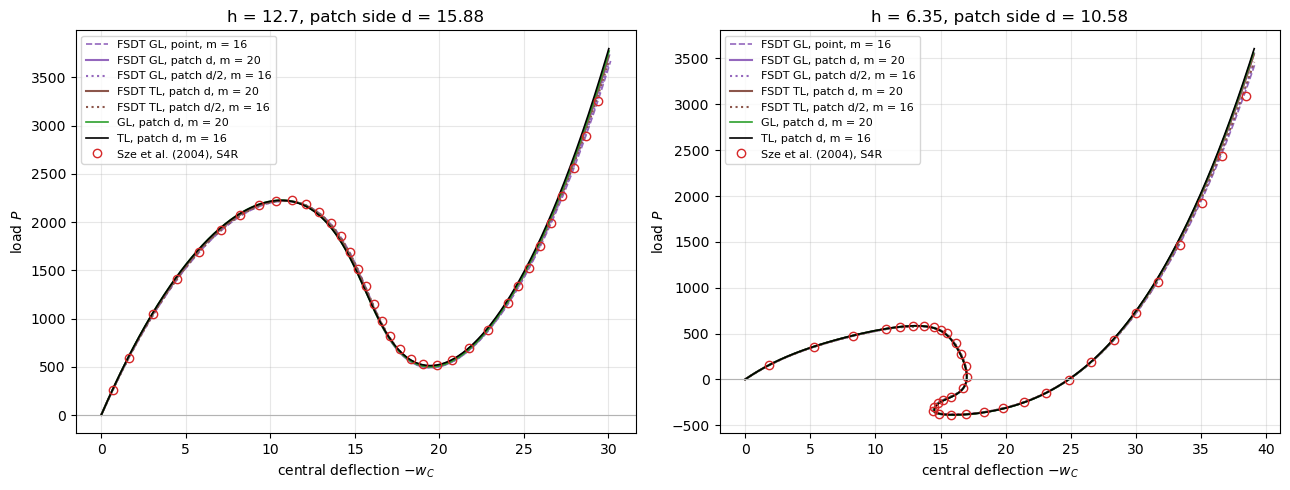

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, h in zip(axes, THICKNESSES):
    o = shear['%s h%g m16 soft' % (FSDT, h)]
    ax.plot(-np.r_[0., o['wc']], np.r_[0., o['P']], color='tab:purple', ls='--', lw=1.2,
            label='FSDT GL, point, m = 16')
    for key, kw in [('%s h%g m%d d' % (FSDT, h, m_list(FSDT, h)[-1]), dict(color='tab:purple', lw=1.5)),
                    ('%s h%g m16 d/2' % (FSDT, h), dict(color='tab:purple', ls=':', lw=1.5)),
                    ('%s h%g m%d d' % (FSDT_TL, h, m_list(FSDT_TL, h)[-1]), dict(color='tab:brown', lw=1.5)),
                    ('%s h%g m16 d/2' % (FSDT_TL, h), dict(color='tab:brown', ls=':', lw=1.5)),
                    ('%s h%g m%d d' % (tt.GL, h, m_list(tt.GL, h)[-1]), dict(color='tab:green', lw=1.2)),
                    ('%s h%g m%d d' % (tt.TL, h, m_list(tt.TL, h)[-1]), dict(color='k', lw=1.2))]:
        P, w, o = ppath(key)
        frac = 'd' if o['frac'] == 1. else 'd/2'
        ax.plot(w, P, label='%s, patch %s, m = %d' % (LABELS[o['model']], frac, o['m']), **kw)
    ref = SZE[h]
    ax.plot(ref[:, 1], tt.PMAX*ref[:, 0], 'o', mfc='none', mec='tab:red', ms=6,
            label='Sze et al. (2004), S4R')
    ax.axhline(0., color='0.7', lw=0.8)
    ax.set_title('h = %g, patch side d = %.2f' % (h, SIDE[h]))
    ax.set_xlabel('central deflection $-w_C$')
    ax.set_ylabel('load $P$')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

- **Convergence.** Under the patch every model converges with $m$, `'cylshell_fsdt_gl'` included: from $m = 12$ to the largest $m$ the load at the end of the paths changes by at most 0.05% ($h = 12.7$; `'cylshell_fsdt_gl'` 3343.9, 3345.6 and 3345.4 for $m$ = 12, 16 and 20) and 0.11% ($h = 6.35$; 3288.7, 3290.8 and 3292.3), and so does that of `'cylshell_fsdt_tl'` (3361.5, 3363.2 and 3363.0; 3288.1, 3290.1 and 3291.6), whereas under the point load it decreases by 1.2% and 3.1% from $m = 8$ to 16 (Section 6). The limit loads of the thick roof are converged to 0.01% with $m = 12$; those of the thin roof need the finer increments of the table above. The point load under load control gives the path of the prescribed deflection of Section 4 (`'cylshell_clpt_sanders'`, $m = 12$: $P_1$ 2229.33 against 2229.37, the end 3272.26 against 3272.45; for $h = 6.35$ $P_1$ 585.63 against 585.84 with the coarse increments, the end 3170.23 against 3170.28).
- **Limit loads.** The patch changes the limit loads little: with $d$ and the converged $m$, $P_1$ is within $-0.18\%$ (`'cylshell_fsdt_gl'`) to $+0.35\%$ (Sanders) of Sze et al. for $h = 12.7$, and within $-0.40\%$ to $+0.05\%$ for $h = 6.35$ (finer increments; `'cylshell_fsdt_tl'` $-0.14\%$ and $-0.30\%$), against $-0.39\%$ to $+0.14\%$ and $-0.47\%$ to $-0.01\%$ under the point load; the minimum $P_2$ and the turns $w_3$, $w_4$ of the snap-back change by less than 0.6%.
- **End of the paths.** The patch makes every model stiffer at the end of the paths than the point load: the four CLPT models alike by 1.7% ($h = 12.7$) and 2.9% ($h = 6.35$) with the side $d$, by 0.5% and 0.9% with $d/2$ (against the converged point-load paths, $m = 14$, Section 4). `'cylshell_fsdt_gl'`, converged, is $+2.92\%$ ($h = 12.7$) and $+6.41\%$ ($h = 6.35$) from Sze et al. with the patch $d$, $+1.25\%$ and $+3.67\%$ with $d/2$; `'cylshell_fsdt_tl'` $+3.46\%$ and $+6.39\%$ with $d$, $+1.78\%$ and $+3.64\%$ with $d/2$; the CLPT models $+2.31\%$ (Sanders) to $+5.23\%$ (TL) and $+5.26\%$ to $+7.82\%$ with $d$.
- **Transverse shear, converged.** With the same patch, `'cylshell_fsdt_gl'` is below `'cylshell_clpt_gl'` at the end of the paths by 1.21% ($d$) and 1.68% ($d/2$) for $h = 12.7$, by 0.83% and 1.43% for $h = 6.35$, and `'cylshell_fsdt_tl'` below `'cylshell_clpt_tl'` by 1.68% and 2.15%, and by 1.37% and 1.96%: the shear lowers the end reaction by about 1% to 2%, more as the patch shrinks, as the logarithmic singularity says, and without limit as the patch becomes a point.
- **Total-Lagrangian against Green-Lagrange kinematics.** With the same patch and $m$, the total-Lagrangian kinematics change the limit loads $P_1$ by less than 0.1%, with and without transverse shear, and raise the minimum $P_2$ of the thick roof by 2.8% (CLPT, 512.22 against 498.35) and 2.9% (FSDT, 507.49 against 493.20), so that `'cylshell_fsdt_tl'` is $-2.16\%$ from Sze et al. there, against $-4.92\%$ for `'cylshell_fsdt_gl'`. At the end of the paths `'cylshell_clpt_tl'` is above `'cylshell_clpt_gl'` by 1.01% ($h = 12.7$) and 0.49% ($h = 6.35$) with both patches; with the transverse shear the difference is smaller: `'cylshell_fsdt_tl'` is above `'cylshell_fsdt_gl'` by 0.53% and 0.52% ($d$ and $d/2$) for $h = 12.7$, and equal to it within 0.03% for $h = 6.35$. The end of the paths of the two FSDT models thus differs from Sze et al. by the same amount for the thin roof, and by 0.5% more with the total-Lagrangian kinematics for the thick roof.
- **What the comparison shows.** At the end of the paths the reaction depends on how the load is concentrated, for the CLPT as much as for the FSDT: spreading it over one S4R element raises the reaction by 1.7% and 2.9%, the size of the differences from Sze et al. found in Section 4, and more than the transverse shear lowers it. The S4R paths are those of a nodal force on a given mesh, a load concentrated over a length of the order of one element, with a shear deflection that depends on that mesh. A converged continuum model reproduces it only up to the choice of the size of the patch: with the tributary area of the central node ($d/2$), the closest of the two, `'cylshell_fsdt_gl'` stays above Sze et al. by 1.25% and 3.67%, `'cylshell_fsdt_tl'` by 1.78% and 3.64%, and the point load lies below. The limit loads are compared within 0.4% whatever the load; the end of the paths only within the few percent that the representation of the nodal load of the S4R mesh leaves open.

## 8. Discussion

- **Snap-back.** Under the prescribed central deflection, the Riks method follows the whole path of the thin roof, $h = 6.35$, with every model: the deflection grows to $-w_C \approx 17.0$, turns back to about 14.5 while the reaction drops to negative values, and grows again; the prescribed displacement $\lambda\delta$ of the spring decreases in 10 increments, the part of the path that a displacement-controlled analysis, which only increases $\lambda\delta$, cannot follow. A load-controlled analysis would stop at the limit load $P_1$.
- **Agreement with Sze et al.** With $12 \times 12$ terms on the quarter (about $24 \times 24$ on the whole roof), the limit loads $P_1$ of the four models are within $-0.29\%$ to $+0.14\%$ of the S4R paths, and the turns of the snap-back, $w_3$ and $w_4$, within $-0.32\%$ to $+1.17\%$; `'cylshell_clpt_tl'` gives $P_1$ within $-0.26\%$ ($h = 12.7$) and $-0.21\%$ ($h = 6.35$), the minimum $P_2$ of the thin roof within $+0.09\%$, and $w_3$, $w_4$ within $+0.02\%$ and $+0.18\%$.
- **Differences between the kinematics.** The roof is shallow, $\theta = 0.1$ rad, and the four models differ by less than 0.5% on the limit loads and by less than 1.5% on the turns of the snap-back of the thin roof. The largest difference is the minimum $P_2$ of the thick roof, after the snap-through, where the cap has inverted: Donnell $-2.25\%$, Sanders $-2.72\%$, Green-Lagrange $-4.05\%$ and total Lagrangian $-1.38\%$ from Sze et al. The complete Green-Lagrange membrane strains with the linear curvatures of Sanders lower $P_2$ by 1.4% from Sanders; measuring the curvatures with the deformed normal raises it by 2.8% from that, the closest of the four to the S4R path.
- **End of the paths.** Where the inverted roof is stretched, at the last deflections of the tables, all models are stiffer than the S4R paths: Sanders by $+0.68\%$ and $+2.47\%$, Donnell and Green-Lagrange by about $+2.5\%$ and $+4.2\%$ to $+4.4\%$, total Lagrangian by $+3.52\%$ and $+4.96\%$ ($h = 12.7$ and $6.35$). These values are converged in $m$ (column $m = 14$). Section 6 shows that the spring and the increments do not change them, and that the transverse shear under the point load, which the S4R elements have and the CLPT has not, lowers the end of the paths by about 2% (FSDT, $m = 16$, not converged), the size of the difference: the FSDT cylinders of panels are within $-1.60\%$ to $+2.23\%$ of Sze et al. there (Donnell, Sanders and Green-Lagrange membrane strains).
- **Patch load.** The shear deflection of the FSDT under a point load has a logarithmic singularity, so that its central deflection grows like $\ln m$ (Section 7, at twice the rate $P/(2\pi\kappa G h)$ of the continuum); with the load spread over one S4R element of the mesh of Sze et al., `'cylshell_fsdt_gl'` converges, to 0.05% and 0.11% at the end of the paths. The patch changes the limit loads by less than 0.5% (all models within $-0.40\%$ to $+0.35\%$ of Sze et al.) but raises the end of the paths of every model, by 1.7% and 2.9% for the CLPT, more than the transverse shear lowers it (1.2% and 0.8% with the same patch): converged, `'cylshell_fsdt_gl'` is $+2.92\%$ and $+6.41\%$ from Sze et al. with the patch of one element and $+1.25\%$ and $+3.67\%$ with the tributary area of the central node, and the total-Lagrangian `'cylshell_fsdt_tl'` $+3.46\%$ and $+6.39\%$, $+1.78\%$ and $+3.64\%$: with the transverse shear the total-Lagrangian kinematics raise the end of the paths by 0.5% for the thick roof and leave it unchanged for the thin one, against 1.0% and 0.5% for the CLPT models. The end of the paths is as sensitive to the representation of the nodal force of the S4R mesh as to the kinematics and the transverse shear.
- **Convergence.** $m = 8$ gives the critical points within 0.1% of $m = 14$ for every model, except the deflection $w_4$ of the thin roof (0.3% to 0.5%); $m = 6$ is 0.5% off for the thin roof. The quarter model with symmetry conditions halves the number of terms along each direction against the whole roof: the whole roof with Sanders' kinematics and $12 \times 12$ terms of the notebook `sze2004_hinged_roofs` has the limit loads 2229.4 and 585.4, the quarter with $12 \times 12$ terms here 2229.4 and 585.8.
- **Cost.** The generated kernels of `'cylshell_clpt_gl'` are the fastest; `'cylshell_clpt_tl'`, with `3p + 1` integration points and cubic curvatures, takes about three times as long, and still less than the kernels of `'cylshell_clpt_sanders'` and `'cylshell_clpt_donnell'` in this problem (column `time`).